# Next-day temperature forecasting with deep learning

**Course project – Deep Learning, Koźmiński University 2026/27** · dataset option 3 in `Grading.md`

**Task:** take the **last three days** of weather data and predict the **temperature of the next day**. `Apparent Temperature (C)` is never used. Regression.

> **Our decision – which temperature?** The brief doesn't specify, so we predict three things about the next day: its **mean, minimum and maximum** temperature (local calendar day). Each has its own baseline "tomorrow = today", and different models may turn out best for different targets.

| Required in the presentation (`Grading.md`) | Where |
|---|---|
| Data exploration and conclusions, and how they shaped the network | §2 (raw data, keep/drop decisions in §2.8), §3 |
| Feature engineering and why | §4 |
| Network architecture, why these models, and why each part is there | §7, §8, §9 |
| Framework and methods, and why | §0, §5, §7 |
| Issues and problems in the data | §2 (**Issue** marks), §12, appendix |

**Method.** We follow the course rules: the reproducible-experiment checklist from Class 1 (`tensors.ipynb`), the tabular baseline and tuning order from Class 2, and target scaling, K-fold validation and final retraining from `regression.ipynb`.

**Files.** Everything – cleaning, features, models, the experiment search and the final evaluation – is in this notebook. `config.yaml` holds every setting, including the search plan. Every training run is logged in `runs/experiments.jsonl`.

## 0. Setup

**Framework: Keras 3 on TensorFlow.** It's the framework used in the course. The functional API (Class 3) lets us combine several inputs (hourly series, daily rows, calendar), and `set_random_seed` plus op determinism make runs exactly repeatable.

In [1]:
import os
os.environ["PYTHONHASHSEED"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import hashlib, json, platform, subprocess, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import keras
import tensorflow as tf

In [2]:
def load_config(path="config.yaml"):
    with open(path) as f:
        return yaml.safe_load(f)


def set_seed(seed):
    keras.utils.set_random_seed(seed)               # Python, NumPy, TensorFlow
    tf.config.experimental.enable_op_determinism()


CONFIG = load_config()
RUNS = Path("runs"); RUNS.mkdir(exist_ok=True)
print("Python", platform.python_version(), "| TensorFlow", tf.__version__, "| Keras", keras.__version__,
      "| pandas", pd.__version__, "| NumPy", np.__version__)
print("Hardware:", platform.machine(), subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"],
      capture_output=True, text=True).stdout.strip(), "(CPU training)")
print("Seeds:", CONFIG["seeds"])

Python 3.12.14 | TensorFlow 2.21.0 | Keras 3.15.1 | pandas 3.0.6 | NumPy 2.5.4
Hardware: arm64 Apple M5 Pro (CPU training)
Seeds: [123, 2137, 15190]


## 1. Data and its version

The dataset's SHA-256 hash is stored in `config.yaml` and checked when loading, so we know exactly which version was used.

Source: Kaggle `arnab132/weather-dataset`, version 1, downloaded 2026-10-22. It contains hourly observations from 2006 to 2016.

In [3]:
raw = pd.read_csv(CONFIG["data"]["path"])
print(raw.shape)
raw.head(3)

(96453, 12)


,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,Partly cloudy throughout the day.
2,2006-04-01 02:00:00.000 +0200,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,Partly cloudy throughout the day.


## 2. Exploratory data analysis – what is in the data and what is worth keeping

Before building anything, we look at every column of the raw file: its type, missing values, unique values, distribution and how it behaves over time. Then we decide what to keep, transform or drop (§2.8), and only then clean the data (§2.9).

*Structural and data-quality checks use all rows. Anything about how a variable relates to the **target** uses only the training years 2006–2013 (§3), so the test year can't influence our choices.*

### 2.1 Overview of the columns

In [4]:
numeric = raw.select_dtypes("number").columns
overview = pd.DataFrame({
    "type": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "unique values": raw.nunique(),
    "zeros %": (100 * (raw[numeric] == 0).mean()).round(2),
    "min": raw[numeric].min().round(2),
    "max": raw[numeric].max().round(2),
    "example": raw.iloc[0].astype(str).str.slice(0, 35),
}).loc[raw.columns]
print(f"{raw.shape[0]:,} rows × {raw.shape[1]} columns | {len(numeric)} numeric, {raw.shape[1] - len(numeric)} text")
overview

96,453 rows × 12 columns | 8 numeric, 4 text


,type,missing,unique values,zeros %,min,max,example
Formatted Date,str,0,96429,NaN,NaN,NaN,2006-04-01 00:00:00.000 +0200
Summary,str,0,27,NaN,NaN,NaN,Partly Cloudy
Precip Type,str,517,2,NaN,NaN,NaN,rain
Temperature (C),float64,0,7574,0.34,-21.82,39.91,9.47222222222222
Apparent Temperature (C),float64,0,8984,0.07,-27.72,39.34,7.388888888888888
Humidity,float64,0,90,0.02,0.00,1.00,0.89
Wind Speed (km/h),float64,0,2484,1.34,0.00,63.85,14.1197
Wind Bearing (degrees),float64,0,360,2.35,0.00,359.00,251.0
Visibility (km),float64,0,949,0.47,0.00,16.10,15.826300000000002
Loud Cover,float64,0,1,100.00,0.00,0.00,0.0


- **96,453 rows** (hourly readings 2006–2016) and **12 columns**: 8 numeric, 3 text (`Summary`, `Precip Type`, `Daily Summary`) and the timestamp as text.
- **Only `Precip Type` has missing values** (517).
- **Issue 4 – `Loud Cover` has a single unique value (0)**, so it can't carry any information.
- `Summary` has 27 labels and `Daily Summary` 214 sentences. Both need to be turned into numbers if we want to use them.
- `Humidity` takes only 90 values: it's stored with 2 decimals (0.00–1.00).

### 2.2 Numeric columns – distributions

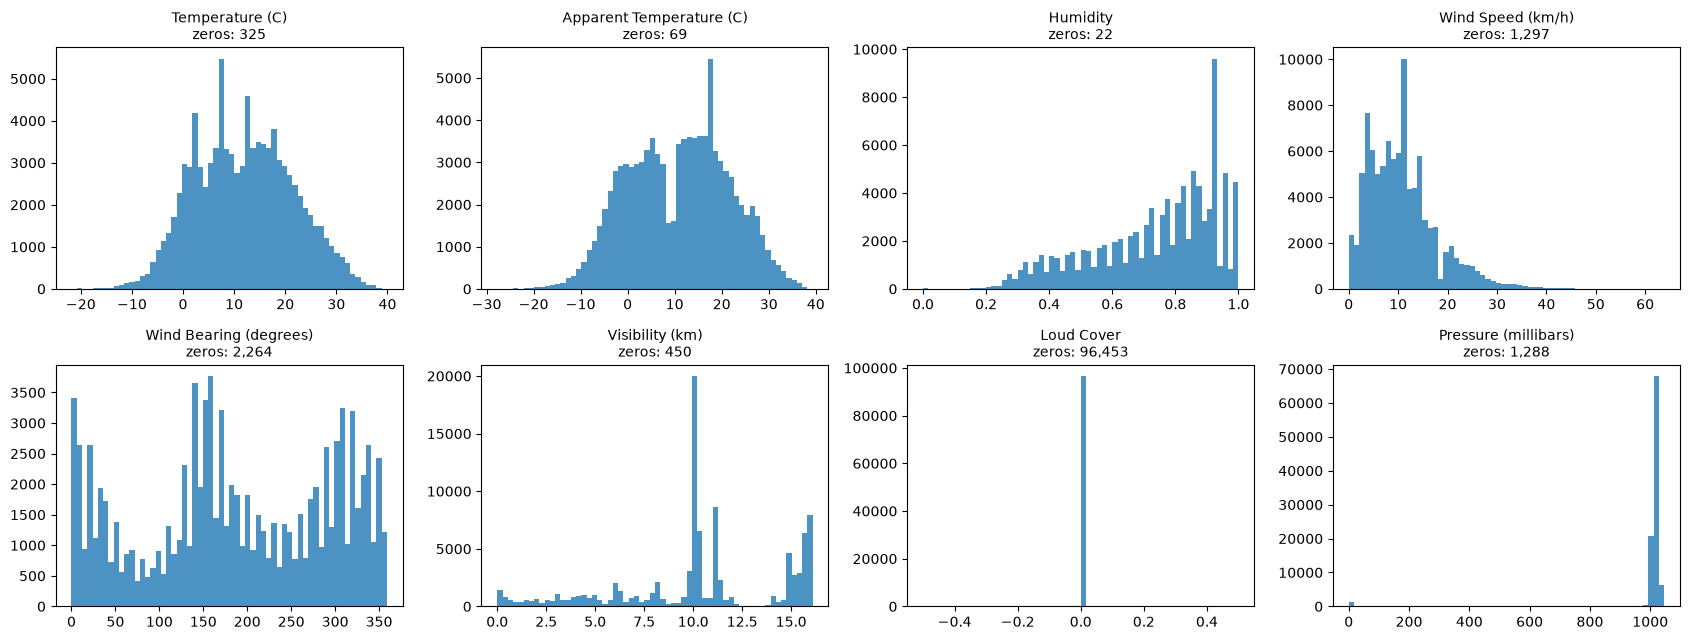

Most common visibility values (km): {9.98: 18290, 16.1: 7092, 15.83: 5683, 11.27: 4580}
Wind speed = 0 (calm): 1,297 hours | wind bearing = 0°: 2,264 hours


,count,mean,std,min,25%,50%,75%,max
Temperature (C),96453.0,11.93,9.55,-21.82,4.69,12.00,18.84,39.91
Apparent Temperature (C),96453.0,10.86,10.70,-27.72,2.31,12.00,18.84,39.34
Humidity,96453.0,0.73,0.20,0.00,0.60,0.78,0.89,1.00
Wind Speed (km/h),96453.0,10.81,6.91,0.00,5.83,9.97,14.14,63.85
Wind Bearing (degrees),96453.0,187.51,107.38,0.00,116.00,180.00,290.00,359.00
Visibility (km),96453.0,10.35,4.19,0.00,8.34,10.05,14.81,16.10
Loud Cover,96453.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Pressure (millibars),96453.0,1003.24,116.97,0.00,1011.90,1016.45,1021.09,1046.38


In [5]:
fig, axes = plt.subplots(2, 4, figsize=(17, 6.5))
for ax, col in zip(axes.ravel(), numeric):
    ax.hist(raw[col], bins=60, color="tab:blue", alpha=0.8)
    ax.set_title(f"{col}\nzeros: {(raw[col] == 0).sum():,}", fontsize=10)
plt.tight_layout(); plt.show()

print("Most common visibility values (km):", raw["Visibility (km)"].round(2).value_counts().head(4).to_dict())
print(f"Wind speed = 0 (calm): {(raw['Wind Speed (km/h)'] == 0).sum():,} hours | "
      f"wind bearing = 0°: {(raw['Wind Bearing (degrees)'] == 0).sum():,} hours")
raw[numeric].describe().T.round(2)

- **Issue 5 – impossible zeros.** `Pressure` is 0 mbar in **1,288 hours**, while real values sit around 1,000–1,045 mbar. `Humidity` is exactly 0 in **22 hours**. Both are sensor failures, i.e. missing data, so we interpolate them in time.
- **Temperature** ranges from −22 to 40 °C with a broad spread (winter to summer). It's the target and our most important input.
- **Visibility** has a hard maximum of **16.1 km (= 10 miles)**, and most readings fall on a few values (9.98, 15.83, 16.1 km). It was probably measured in miles and rounded. It's still a valid measurement, so we keep it and check later whether it helps. Visibility 0 (450 hours) is possible in dense fog, so we keep those too.
- **Wind bearing** is an angle from 0° to 359°. As a plain number, 359° and 1° look far apart even though they're neighbours, and the bearing means nothing when the wind is calm (speed 0). So we turn speed + bearing into **east/north wind components** (§4).
- **Humidity = 1.0** (2,890 hours) is plausible: saturated air, e.g. fog. We keep it.

### 2.3 Text columns – values

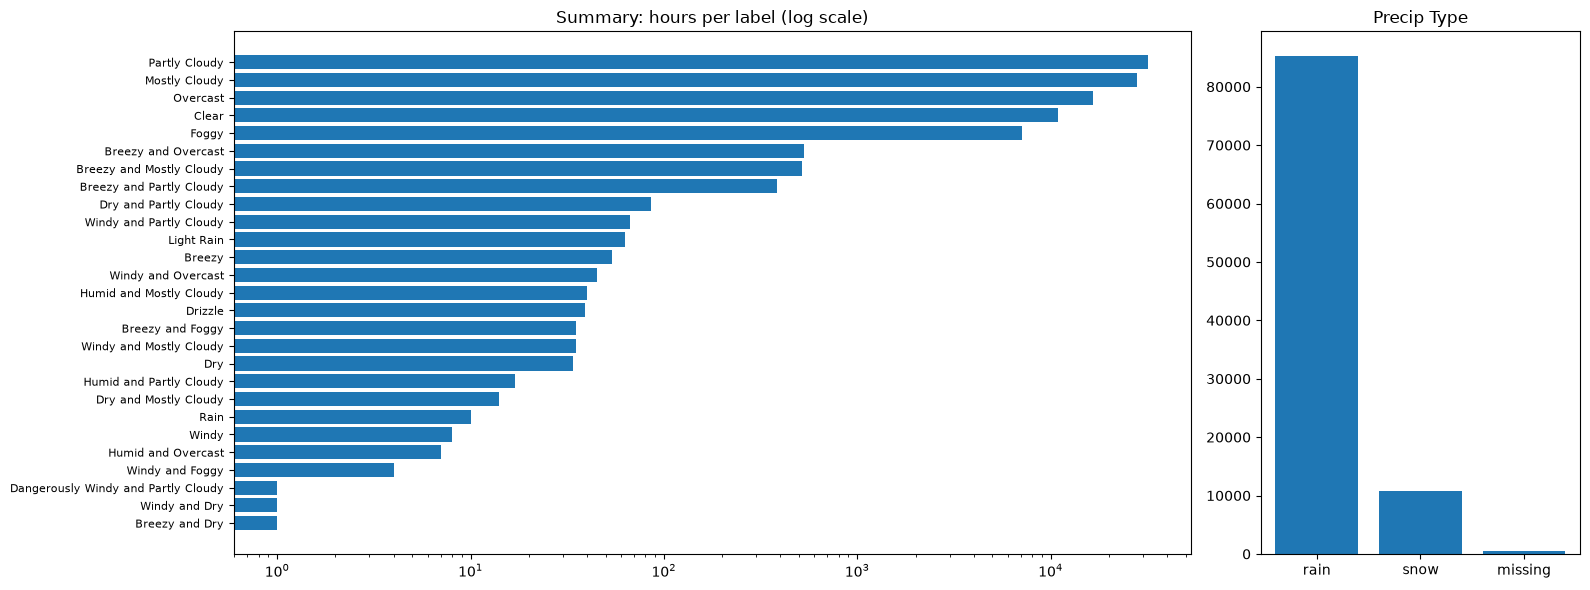

Daily Summary: 214 different sentences; different sentences within one day: 1 (always the same for all hours of a day)
Daily Summary
Mostly cloudy throughout the day.         20085
Partly cloudy throughout the day.          9981
Partly cloudy until night.                 6169
Partly cloudy starting in the morning.     5184
Foggy in the morning.                      4201


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [3, 1]})
vc = raw["Summary"].value_counts()
ax[0].barh(vc.index[::-1], vc.values[::-1]); ax[0].set_xscale("log")
ax[0].set_title("Summary: hours per label (log scale)"); ax[0].tick_params(axis="y", labelsize=8)
pt = raw["Precip Type"].fillna("missing").value_counts()
ax[1].bar(pt.index, pt.values); ax[1].set_title("Precip Type")
plt.tight_layout(); plt.show()

per_day = raw.assign(day=raw["Formatted Date"].str.slice(0, 10)).groupby("day")["Daily Summary"].nunique()
print(f"Daily Summary: {raw['Daily Summary'].nunique()} different sentences; "
      f"different sentences within one day: {per_day.max()} (always the same for all hours of a day)")
print(raw["Daily Summary"].value_counts().head(5).to_string())

- **`Summary`** is dominated by five cloud/fog labels (Partly Cloudy, Mostly Cloudy, Overcast, Clear, Foggy), which cover 98 % of hours. The rest are combinations with *Breezy/Windy/Dry/Humid* and a few rain labels. The useful content is **cloud cover, fog and wind**, so we extract those as numbers (§4).
- **`Precip Type`** has only `rain`, `snow` or missing. Almost every hour has a value, even clear ones, so it's suspicious; see §2.5.
- **`Daily Summary`** is **one sentence per day**, repeated for all its hours (e.g. "Mostly cloudy throughout the day."). We can only use it for the past days, never for the day we predict, and only via text methods (a bag of words, Class 2).

### 2.4 The time axis

In [7]:
t = pd.to_datetime(raw["Formatted Date"], utc=True)
print("UTC offsets in the timestamps:", raw["Formatted Date"].str.slice(-5).value_counts().to_dict())
print("File sorted by time:", t.is_monotonic_increasing)
print("Fully duplicated rows:", raw.duplicated().sum(), "| duplicated timestamps:", t.duplicated().sum(),
      "| on the dates:", sorted(set(raw.loc[t.duplicated(keep=False), "Formatted Date"].str.slice(0, 10))))
gaps = t.drop_duplicates().sort_values().diff().value_counts()
print("Time steps between readings:", {str(k): v for k, v in gaps.items()})
local = t.drop_duplicates().dt.tz_convert(CONFIG["data"]["timezone"])
hours_per_day = local.dt.date.value_counts()
print("Hours per local day:", hours_per_day.value_counts().sort_index().to_dict(),
      "| incomplete:", hours_per_day[hours_per_day < 23].to_dict())
print("Rows per year:", local.dt.year.value_counts().sort_index().to_dict())

UTC offsets in the timestamps: {'+0200': 56469, '+0100': 39984}
File sorted by time: False
Fully duplicated rows: 24 | duplicated timestamps: 24 | on the dates: ['2010-08-02']
Time steps between readings: {'0 days 01:00:00': 96427, '0 days 04:00:00': 1}
Hours per local day: {21: 1, 23: 11, 24: 3995, 25: 11} | incomplete: {datetime.date(2014, 7, 14): 21}
Rows per year: {2006: 8760, 2007: 8760, 2008: 8784, 2009: 8760, 2010: 8760, 2011: 8760, 2012: 8784, 2013: 8760, 2014: 8757, 2015: 8760, 2016: 8784}


- **Issue 1 – mixed time zones.** Timestamps switch between `+0100` (winter) and `+0200` (summer, daylight saving). We parse everything to UTC and convert to local time (`Europe/Budapest`), so "a day" is a real local calendar day. Days with 23 or 25 hours are the DST switches.
- **Issue 2 – the file isn't sorted by time.** We have to sort before building any 3-day windows.
- **Issue 3 – 24 fully duplicated rows:** the whole day 2010-08-02 appears twice. We drop the duplicates.
- **Issue 7 – a few missing hours.** There's one 4-hour gap (2014-07-14 has only 21 hours). Daily averages handle this. For the hourly model input we use a regular hourly grid and interpolate the gap.
- Otherwise every year 2006–2016 has all its hours. Whether all of them are *real* is checked in §2.7.

### 2.5 Redundant and forbidden columns

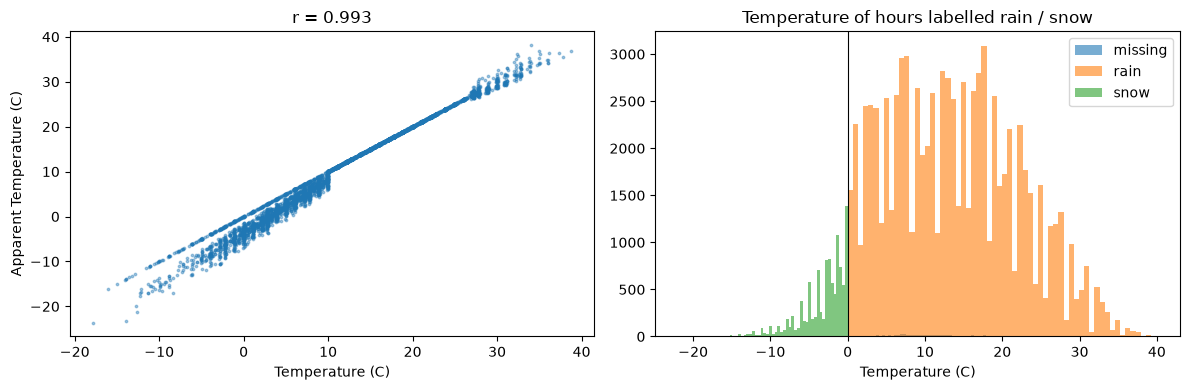

hours with,temperature > 0 °C,temperature ≤ 0 °C
Precip Type,,
missing,517,0
rain,85224,0
snow,0,10712


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
s = raw.sample(5000, random_state=0)
ax[0].scatter(s["Temperature (C)"], s["Apparent Temperature (C)"], s=3, alpha=0.4)
ax[0].set_xlabel("Temperature (C)"); ax[0].set_ylabel("Apparent Temperature (C)")
ax[0].set_title(f"r = {raw['Temperature (C)'].corr(raw['Apparent Temperature (C)']):.3f}")
for name, g in raw.groupby(raw["Precip Type"].fillna("missing")):
    ax[1].hist(g["Temperature (C)"], bins=60, alpha=0.6, label=name)
ax[1].axvline(0, color="k", lw=0.8); ax[1].legend(); ax[1].set_xlabel("Temperature (C)")
ax[1].set_title("Temperature of hours labelled rain / snow")
plt.tight_layout(); plt.show()
pd.crosstab(raw["Precip Type"].fillna("missing"), np.where(raw["Temperature (C)"] <= 0, "temperature ≤ 0 °C", "temperature > 0 °C"),
            rownames=["Precip Type"], colnames=["hours with"])

- **`Apparent Temperature`** (the "feels like" temperature) is almost a copy of the temperature (r = 0.993). The brief forbids using it, and it would also be close to cheating. We drop it right at loading so it can't leak into anything.
- **Issue 6 – `Precip Type` is not precipitation.** The table shows a perfect split: **every** `snow` hour is at ≤ 0 °C and **every** `rain` hour above 0 °C. The column is just "is it freezing?", so it repeats information we already have from the temperature. We drop it.

### 2.6 Rare labels over time

In [9]:
year = t.dt.tz_convert(CONFIG["data"]["timezone"]).dt.year.rename("year")
rare = vc[vc < 1000].index
rare_by_year = pd.crosstab(raw.loc[raw["Summary"].isin(rare), "Summary"], year[raw["Summary"].isin(rare)])
rain = raw["Summary"].str.contains("Rain|Drizzle")
print("Hours with a rain label per year:", year[rain].value_counts().sort_index().to_dict())
rare_by_year

Hours with a rain label per year: {2012: 22, 2016: 90}


year,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016
Summary,,,,,,,,,,,
Breezy,2,11,3,6,2,3,4,1,13,8,1
Breezy and Dry,0,0,0,0,0,0,1,0,0,0,0
Breezy and Foggy,7,0,0,0,2,0,14,10,1,1,0
Breezy and Mostly Cloudy,40,38,68,71,39,29,61,55,44,61,10
Breezy and Overcast,31,31,31,88,52,25,46,67,69,39,49
Breezy and Partly Cloudy,32,57,45,51,31,34,50,30,9,32,15
Dangerously Windy and Partly Cloudy,0,1,0,0,0,0,0,0,0,0,0
Drizzle,0,0,0,0,0,0,5,0,0,0,34
Dry,0,14,3,2,0,0,14,1,0,0,0


- **Issue 8 – rain labels exist almost only in the test year.** "Light Rain", "Rain" and "Drizzle" appear in **22 hours of 2012** and **90 hours of 2016**, and never in any other year. With only 22 hours in all the training years, a model can't learn what rain means. It would also see rain in 2016 far more often than ever in training. So we **don't use a rain feature**. (We first noticed this when one K-fold fold blew up: with 2012 held out, the training data had no rain at all, so its standard deviation was 0. Scaling now handles such cases safely; see `safe_std`.)
- **"Dry"** and **"Humid"** labels are rare too, and concentrated in a few years (e.g. "Dry and Mostly Cloudy" only in 2012). We don't build features from them. *Breezy/Windy* labels appear in every year, so the **windy** flag is safe to use.

### 2.7 Is every day real? Copied days at the end of 2016

Days that are (almost) exact copies of the previous day, per year: {2006: 0, 2007: 0, 2008: 0, 2009: 0, 2010: 0, 2011: 0, 2012: 0, 2013: 0, 2014: 0, 2015: 0, 2016: 57}
First and last copied day: 2016-11-04 → 2016-12-31


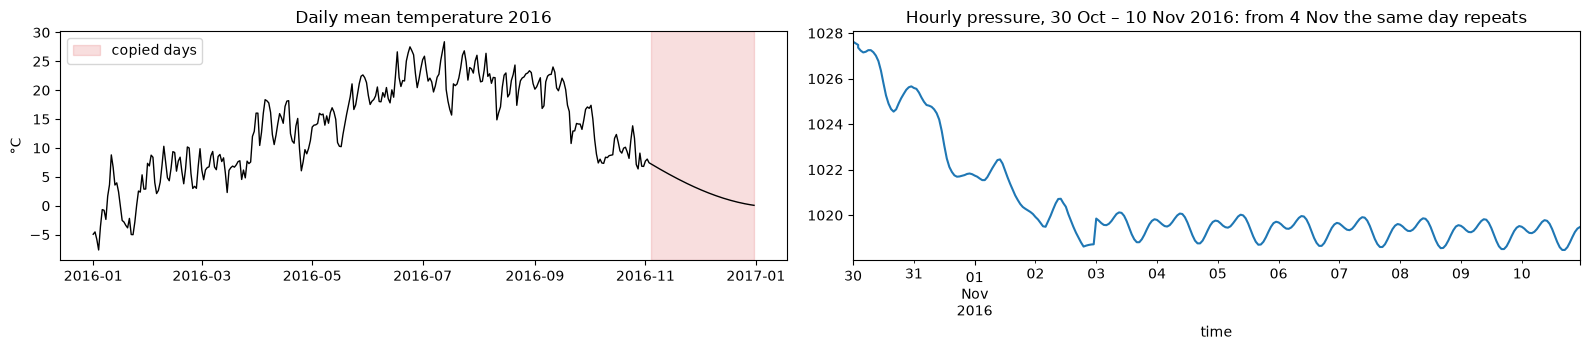

,Humidity,Pressure (millibars),Wind Speed (km/h)
time,,,
2016-10-31 00:00:00+01:00,0.13,3.86,10.473
2016-11-01 00:00:00+01:00,0.07,3.86,19.368
2016-11-02 00:00:00+01:00,0.13,2.05,12.800
2016-11-03 00:00:00+01:00,0.08,1.10,8.710
2016-11-04 00:00:00+01:00,0.01,0.06,0.113
2016-11-05 00:00:00+01:00,0.01,0.06,0.113
2016-11-06 00:00:00+01:00,0.01,0.06,0.161
2016-11-07 00:00:00+01:00,0.01,0.06,0.161


In [10]:
r = raw.assign(time=t.dt.tz_convert(CONFIG["data"]["timezone"])).drop_duplicates("time").set_index("time").sort_index()
day_of = r.index.normalize()
# Largest hourly difference between a day's profile and the previous day's profile, per variable
same_as_yesterday = pd.DataFrame({
    col: r[col].groupby([day_of, r.index.hour]).mean().unstack().diff().abs().max(axis=1)
    for col in ["Humidity", "Pressure (millibars)", "Wind Speed (km/h)"]})
copied = ((same_as_yesterday["Humidity"] < 0.02) & (same_as_yesterday["Pressure (millibars)"] < 0.5)
          & (same_as_yesterday["Wind Speed (km/h)"] < 0.5))
print("Days that are (almost) exact copies of the previous day, per year:",
      copied.groupby(copied.index.year).sum().to_dict())
print("First and last copied day:", copied[copied].index.min().date(), "→", copied[copied].index.max().date())

daily_mean_2016 = r["Temperature (C)"]["2016"].resample("D").mean()
fig, ax = plt.subplots(1, 2, figsize=(16, 3.6))
ax[0].plot(daily_mean_2016.index, daily_mean_2016.values, color="k", lw=1)
ax[0].axvspan(copied[copied].index.min(), daily_mean_2016.index.max(), color="tab:red", alpha=0.15, label="copied days")
ax[0].set_title("Daily mean temperature 2016"); ax[0].set_ylabel("°C"); ax[0].legend()
r.loc["2016-10-30":"2016-11-10", "Pressure (millibars)"].plot(ax=ax[1], color="tab:blue")
ax[1].set_title("Hourly pressure, 30 Oct – 10 Nov 2016: from 4 Nov the same day repeats")
plt.tight_layout(); plt.show()
same_as_yesterday.loc["2016-10-31":"2016-11-07"].round(3)

- **Issue 9 – the last 57 days of 2016 are artificial.** From **4 November to 31 December 2016**, every day is an almost exact copy of the day before. Humidity, pressure and wind repeat the same 24-hour profile (pressure differs by ≤ 0.06 mbar between days, against several mbar normally), and the temperature drifts down smoothly with no weather at all. **No other year has a single copied day.** Real data ends on 3 November 2016.
- *Consequence:* these days fall in our **test year**. On them, "tomorrow = today" is almost perfect by construction, while the model gets unrealistic inputs. So the test set is **1 January – 3 November 2016 (308 days)** (`valid_until` in `config.yaml`). Training and all model choices (2006–2015) are unaffected.
- *How we found it:* the plots of predicted vs actual values in §10 showed a perfectly smooth "actual" curve in November–December. We then added this check. The model wasn't changed; only the test days were corrected.

### 2.8 Decision: what we keep, transform or drop

| Column | Decision | Reason (evidence) |
|---|---|---|
| `Formatted Date` | **transform** → timestamp in local time; hour of day and day of year | mixed UTC offsets, unsorted, duplicates (§2.4) |
| *days after 3 Nov 2016* | **exclude** from evaluation | artificial copies of the previous day (§2.7) |
| `Temperature (C)` | **keep** (target and input) | the variable we predict; strongest signal (§3) |
| `Apparent Temperature (C)` | **drop** | forbidden by the brief; a near copy of temperature (r = 0.993, §2.5) |
| `Humidity` | **keep**, zeros → interpolated; plus **dew point** derived with temperature | 22 impossible zeros (§2.2); moisture affects night-time cooling |
| `Wind Speed (km/h)` | **keep** | most informative single variable for tomorrow's change (§3) |
| `Wind Bearing (degrees)` | **transform** → east/north wind components (with speed) | an angle: 359° ≈ 1°, meaningless at calm (§2.2) |
| `Visibility (km)` | **keep** (checked later) | valid but coarse, capped at 16.1 km; weak signal (§3); no measurable effect in the ablation (§8) |
| `Loud Cover` | **drop** | a single value (0) in every row (§2.1) |
| `Pressure (millibars)` | **keep**, zeros → interpolated; plus **daily pressure change** | 1,288 impossible zeros (§2.2); pressure trends signal fronts (§3) |
| `Precip Type` | **drop** | exactly "temperature ≤ 0 °C" (§2.5) |
| `Summary` | **transform** → cloudiness (0–3), fog flag, windy flag; **no rain flag** | 27 labels, 98 % about clouds/fog (§2.3); rain labels only in 2012/2016 (§2.6) |
| `Daily Summary` | **only as an optional text experiment** | one sentence per day (§2.3); tested as a bag of words in the preliminary experiments and **rejected** (it made results worse; appendix) |

### 2.9 Cleaning – applying the decisions

`load_clean` reads the file, checks its hash and applies the decisions above.

In [11]:
RENAME = {
    "Temperature (C)": "temp", "Humidity": "humidity", "Wind Speed (km/h)": "wind_speed",
    "Wind Bearing (degrees)": "wind_bearing", "Visibility (km)": "visibility",
    "Pressure (millibars)": "pressure", "Precip Type": "precip_type",
    "Summary": "summary", "Daily Summary": "daily_summary",
}


def load_clean(cfg, verbose=False):
    """Read the CSV, check its hash and fix the data issues found during exploration."""
    path = Path(cfg["data"]["path"])
    sha = hashlib.sha256(path.read_bytes()).hexdigest()
    assert sha == cfg["data"]["sha256"], f"Dataset changed! hash = {sha}"
    df = pd.read_csv(path)
    log = {}
    # Mixed +01:00/+02:00 offsets (daylight saving time): parse as UTC, then convert to local time.
    df["time"] = pd.to_datetime(df["Formatted Date"], utc=True).dt.tz_convert(cfg["data"]["timezone"])
    log["sorted_in_file"] = bool(df["time"].is_monotonic_increasing)
    df = df.sort_values("time")
    log["duplicate_timestamps"] = int(df["time"].duplicated().sum())
    df = df.drop_duplicates(subset="time").set_index("time")
    log["loud_cover_unique"] = df["Loud Cover"].unique().tolist()
    log["pressure_zero_rows"] = int((df["Pressure (millibars)"] == 0).sum())
    log["humidity_zero_rows"] = int((df["Humidity"] == 0).sum())
    for col in ["Pressure (millibars)", "Humidity"]:   # 0 mbar / 0 % humidity = sensor fault
        df[col] = df[col].replace(0, np.nan).interpolate(method="time")
    # The forbidden column is dropped immediately so it can't leak anywhere.
    df = df.drop(columns=["Apparent Temperature (C)", "Loud Cover", "Formatted Date"]).rename(columns=RENAME)
    if verbose:
        for k, v in log.items():
            print(f"{k}: {v}")
    return df

In [12]:
df = load_clean(CONFIG, verbose=True)
print(df.shape, "| from", df.index.min(), "to", df.index.max())

sorted_in_file: False
duplicate_timestamps: 24
loud_cover_unique: [0.0]
pressure_zero_rows: 1288
humidity_zero_rows: 22
(96429, 9) | from 2006-01-01 00:00:00+01:00 to 2016-12-31 23:00:00+01:00


`load_clean` applied the fixes from §2.1–2.7:
- converted mixed UTC offsets to local time (Issue 1) and sorted the rows (Issue 2)
- dropped the 24 duplicated rows (Issue 3)
- interpolated the impossible zeros in pressure and humidity (Issue 5)
- dropped `Apparent Temperature` (forbidden), `Loud Cover` (constant, Issue 4) and the raw timestamp text

`Precip Type` (Issue 6) and the rain labels (Issue 8) are left in the table but never used as features; the missing hours (Issue 7) are interpolated when the hourly input is built (§5); and days after 3 November 2016 (Issue 9) are never predicted (§5, `valid_until`).

## 3. Exploration

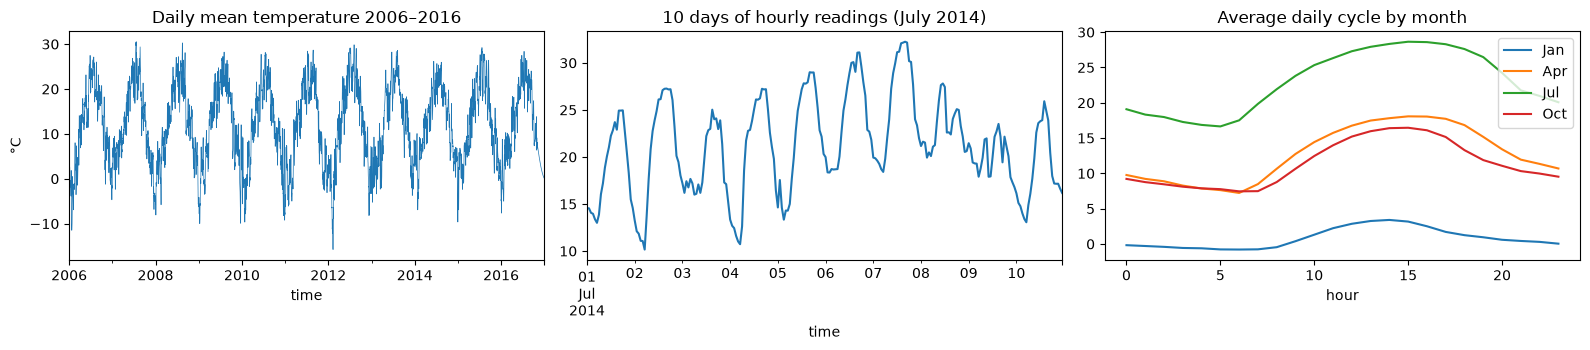

In [13]:
daily_temp = df["temp"].resample("D").mean()
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
daily_temp.plot(ax=ax[0], lw=0.5); ax[0].set_title("Daily mean temperature 2006–2016"); ax[0].set_ylabel("°C")
df["temp"].loc["2014-07-01":"2014-07-10"].plot(ax=ax[1]); ax[1].set_title("10 days of hourly readings (July 2014)")
by_hour = df.groupby([df.index.month, df.index.hour])["temp"].mean().unstack(0)
by_hour[[1, 4, 7, 10]].plot(ax=ax[2]); ax[2].set_title("Average daily cycle by month"); ax[2].set_xlabel("hour")
ax[2].legend(["Jan", "Apr", "Jul", "Oct"])
plt.tight_layout(); plt.show()

**Conclusions**
- **Yearly cycle** (about 25 °C between winter and summer). It's fully predictable from the calendar, so the model gets the day of the year of the predicted day as a feature. This isn't leakage: the date is always known in advance.
- **Daily cycle** (about 5–12 °C between night and afternoon, larger in summer). A daily average hides this shape and the most recent hours. That motivated trying the **hourly** sequence as input, which turned out to be the most important input for the next-day mean and max (§7, §8).

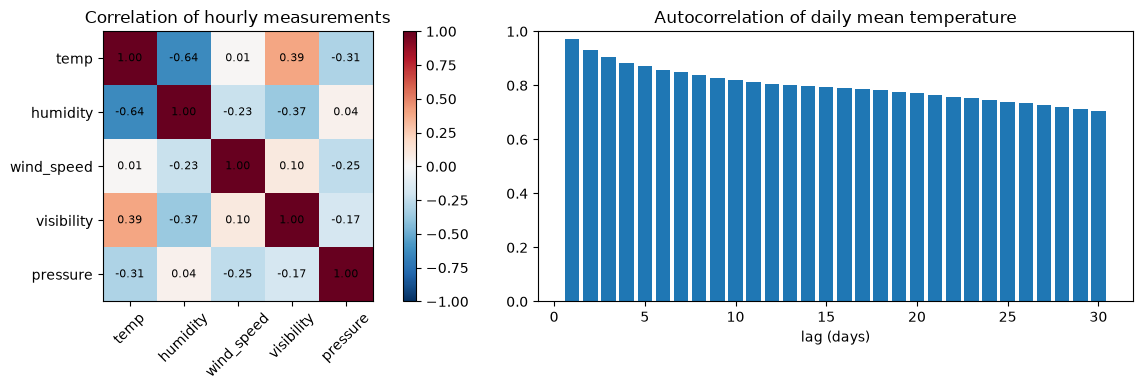

Day-to-day change of the daily mean: mean |change| = 1.63 °C, std = 2.16 °C, largest drop = -11.0 °C, largest rise = 11.3 °C


In [14]:
num = df[["temp", "humidity", "wind_speed", "visibility", "pressure"]]
corr = num.corr()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
im = ax[0].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); fig.colorbar(im, ax=ax[0])
ax[0].set_xticks(range(len(corr)), corr.columns, rotation=45); ax[0].set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax[0].text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax[0].set_title("Correlation of hourly measurements")
lags = range(1, 31)
ax[1].bar(lags, [daily_temp.autocorr(l) for l in lags])
ax[1].set_title("Autocorrelation of daily mean temperature"); ax[1].set_xlabel("lag (days)"); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

change = daily_temp.diff().dropna()
print(f"Day-to-day change of the daily mean: mean |change| = {change.abs().mean():.2f} °C, "
      f"std = {change.std():.2f} °C, largest drop = {change.min():.1f} °C, largest rise = {change.max():.1f} °C")

**Conclusions**
- Lag-1 autocorrelation ≈ 0.97: tomorrow is usually close to today. "Tomorrow = today" (**persistence**) is a strong baseline that every model must beat.
- Because tomorrow ≈ today, we also test predicting the **change** (tomorrow − today) instead of the absolute value (all networks in §7 do this; §8 measures what it's worth).
- Humidity is strongly anti-correlated with temperature. Pressure barely correlates with temperature directly, but pressure *changes* signal weather fronts, so we keep it and also compute its daily change.
- The daily mean usually changes by about 1.6 °C from one day to the next, but sometimes by up to 11 °C (cold fronts, sudden warm-ups). These jumps are the hardest days to predict (§10).

### Which variables say something about tomorrow? (training years only)

Correlation with tomorrow's mean is easy: today's temperature alone gives r = 0.97. The hard part is the **change** from today to tomorrow, so we measure each variable's relationship with it. We use the Pearson correlation *r* (linear) and the **mutual information** (MI, any kind of relationship; 0 = none). Only the training years 2006–2013 are used.

In [15]:
from sklearn.feature_selection import mutual_info_regression

rad = np.deg2rad(df["wind_bearing"])
hv = pd.DataFrame({
    "temperature": df["temp"], "humidity": df["humidity"], "visibility": df["visibility"],
    "pressure": df["pressure"], "wind speed": df["wind_speed"],
    "wind bearing (raw angle)": df["wind_bearing"],
    "wind east component": df["wind_speed"] * np.sin(rad), "wind north component": df["wind_speed"] * np.cos(rad),
    "snow label (Precip Type)": (df["precip_type"] == "snow").astype(float),
})
day = hv.resample("D").mean()
day["pressure change during the day"] = df["pressure"].resample("D").last() - df["pressure"].resample("D").first()
day.index = day.index.tz_localize(None)
tomorrow = day["temperature"].shift(-1)
change = tomorrow - day["temperature"]
m = (day.index <= CONFIG["data"]["train_end"]) & tomorrow.notna()
signal = pd.DataFrame([{
    "variable (today)": c,
    "r with tomorrow's mean": day.loc[m, c].corr(tomorrow[m]),
    "r with tomorrow's change": day.loc[m, c].corr(change[m]),
    "MI with tomorrow's change": mutual_info_regression(day.loc[m, [c]], change[m], random_state=0)[0],
} for c in day.columns]).sort_values("MI with tomorrow's change", ascending=False)
signal.round(3)

,variable (today),r with tomorrow's mean,r with tomorrow's change,MI with tomorrow's change
4,wind speed,-0.181,-0.216,0.077
7,wind north component,-0.056,-0.135,0.056
5,wind bearing (raw angle),0.023,-0.076,0.041
0,temperature,0.970,-0.123,0.041
9,pressure change during the day,-0.089,-0.167,0.032
8,snow label (Precip Type),-0.666,0.114,0.031
6,wind east component,0.027,0.122,0.028
3,pressure,-0.278,0.184,0.024
2,visibility,0.563,-0.094,0.006
1,humidity,-0.598,0.046,0.000


**Conclusions**
- **No single variable predicts the change well** (all |r| ≤ 0.22). A useful model has to **combine** several variables, possibly non-linearly, which is what a neural network is good at.
- The most informative variables for the change are **wind speed**, the **north–south wind component** (northerly wind brings cold air), the **pressure change** and the **pressure level**. These are exactly the weather-front signals, so we keep them.
- **Visibility** and **humidity alone** carry almost no information about the change. Humidity is still kept, because combined with temperature it gives the dew point (moisture), and the ablation in §8 shows that moisture helps (clearly for the mean and the min). Removing visibility made no measurable difference for any target (§8), as this analysis suggested.
- The **snow label** only correlates with tomorrow's mean through temperature (r = −0.67), which confirms the drop decision in §2.5.
- The **raw wind angle** carries some information (MI 0.041) but almost no linear correlation (r = −0.08). What matters is where the wind comes from, and a plain angle encodes that badly (359° and 1° look far apart). The east/north components express the same information continuously; the north component alone reaches MI 0.056.

## 4. Feature engineering

**Hourly features** (computed for every hour; `hourly_features` below):

| Feature | Why |
|---|---|
| temperature, humidity, visibility, pressure | raw measurements (standardised) |
| **dew point** (Magnus formula) | combines temperature and humidity into the actual amount of moisture in the air. Moist air cools less at night. |
| wind speed + **wind u/v components** | the wind direction is an angle (359° and 1° are neighbours), so it's turned into east/north vectors |
| **cloudiness, fog, windy** | numeric versions of the `Summary` text; clouds limit daytime heating and night-time cooling. No rain flag (Issue 8). |
| **hour of day** (sin, cos) | lets the model know where in the daily cycle each reading is |

**Daily features** (one row per day; `daily_table` below): mean, min and max temperature, the **last-hour temperature**, the **temperature trend over the last 6 hours**, mean humidity, dew point, visibility, pressure, **pressure change during the day**, wind, and cloudiness/fog/wind fractions.

**Calendar:** the day of the year of the *predicted* day as sin/cos, so 31 Dec and 1 Jan are neighbours.

In [16]:
CLOUD = {"Partly Cloudy": 1, "Mostly Cloudy": 2, "Overcast": 3, "Clear": 0}


def _cloudiness(s):
    for name, v in CLOUD.items():   # "Partly/Mostly Cloudy" checked before plain words
        if name in s:
            return v
    return np.nan


def hourly_features(df):
    """Numeric hourly features (used both for daily aggregates and the hourly model input)."""
    h = pd.DataFrame(index=df.index)
    h["temp"] = df["temp"]
    h["humidity"] = df["humidity"]
    # Dew point (Magnus formula): the temperature at which air becomes saturated.
    # Combines temperature and humidity into the amount of moisture in the air.
    a, b = 17.62, 243.12
    gamma = np.log(df["humidity"].clip(lower=0.01)) + a * df["temp"] / (b + df["temp"])
    h["dew_point"] = b * gamma / (a - gamma)
    h["visibility"] = df["visibility"]
    h["pressure"] = df["pressure"]
    rad = np.deg2rad(df["wind_bearing"])        # angle -> vector, so 359° and 1° are close
    h["wind_speed"] = df["wind_speed"]
    h["wind_u"] = df["wind_speed"] * np.sin(rad)
    h["wind_v"] = df["wind_speed"] * np.cos(rad)
    h["cloudiness"] = df["summary"].map(_cloudiness)
    h["cloudiness"] = h["cloudiness"].fillna(h["cloudiness"].rolling(6, min_periods=1).mean()).fillna(1.5)
    h["fog"] = df["summary"].str.contains("Fog").astype(float)
    h["windy"] = df["summary"].str.contains("Breezy|Windy").astype(float)
    # No "rain" flag: rain labels appear only in 2012 (22 h) and 2016 (90 h) - see Issue 8.
    return h

In [17]:
def daily_table(df, h):
    """One row per local calendar day."""
    g = h.resample("D")
    d = pd.DataFrame({
        "temp_mean": g["temp"].mean(), "temp_min": g["temp"].min(), "temp_max": g["temp"].max(),
        "temp_last": g["temp"].last(),
        # temperature change over the last 6 hours of the day (evening trend)
        "temp_trend_6h": g["temp"].last() - h["temp"].resample("D").apply(lambda s: s.iloc[-7] if len(s) >= 7 else s.iloc[0]),
        "humidity": g["humidity"].mean(), "dew_point": g["dew_point"].mean(),
        "visibility": g["visibility"].mean(),
        "pressure": g["pressure"].mean(), "pressure_change": g["pressure"].last() - g["pressure"].first(),
        "wind_speed": g["wind_speed"].mean(), "wind_u": g["wind_u"].mean(), "wind_v": g["wind_v"].mean(),
        "cloudiness": g["cloudiness"].mean(), "fog": g["fog"].mean(), "windy": g["windy"].mean(),
    })
    d["daily_summary"] = df["daily_summary"].resample("D").first()
    d.index = d.index.tz_localize(None).normalize()
    num = d.columns.drop("daily_summary")
    d[num] = d[num].interpolate()
    d["daily_summary"] = d["daily_summary"].ffill()
    return d


FEATURE_GROUPS = {
    "temperature": ["temp_mean", "temp_min", "temp_max", "temp_last", "temp_trend_6h"],
    "moisture": ["humidity", "dew_point"],
    "visibility": ["visibility"],
    "pressure": ["pressure", "pressure_change"],
    "wind": ["wind_speed", "wind_u", "wind_v"],
    "sky": ["cloudiness", "fog", "windy"],
}


HOURLY_COLS = ["temp", "humidity", "dew_point", "visibility", "pressure",
               "wind_speed", "wind_u", "wind_v", "cloudiness", "fog", "windy"]

## 5. Windows, split and normalisation

- **Sample:** for a target day *t*, the inputs are days *t-3, t-2, t-1* (as 3 daily rows and/or the 72 hourly rows before local midnight). The targets are the **mean, minimum and maximum** temperature of day *t* (and, for one output design, its 24 hourly temperatures).
- **Split by time, not at random.** Neighbouring days are nearly identical, so a random split would leak test information into training (temporal leakage, Class 1). We use:
  train **2006–2013** · validation **2014–2015** (all model choices) · test **1 Jan – 3 Nov 2016** (the rest of 2016 is artificial, Issue 9).
- **Normalisation** statistics (mean/std) come **from the training rows only**. The **target is scaled too** (`regression.ipynb`: "we can simply scale the outputs and then scale them back"). Predictions are converted back to °C before computing errors.
- **Metric: MAE in °C** – "on average we are X degrees off". **Loss: MSE** (Class 2 recommendation for regression).

`Dataset` builds every sample at once: the 3 daily rows, the 72 hourly rows, the calendar values, the 3 `Daily Summary` sentences and the target. `mask()` returns which samples belong to train, validation, test or a block of years (for K-fold).

In [18]:
class Dataset:
    """All model inputs for every target day, plus the time-based split.

    Sample for target day t: days t-3..t-1 (daily rows, 72 hourly rows, 3 daily summaries)
    + day-of-year of t  ->  mean temperature of day t.
    """

    def __init__(self, cfg, verbose=False):
        self.cfg = cfg
        df = load_clean(cfg, verbose=verbose)
        self.hourly_raw = df
        h = hourly_features(df)
        self.daily = daily_table(df, h)
        W = cfg["data"]["window_days"]

        # Regular UTC hourly grid (no DST jumps); fill the few missing hours by interpolation.
        hu = h.tz_convert("UTC")
        hu = hu.reindex(pd.date_range(hu.index.min(), hu.index.max(), freq="h")).interpolate()
        hour_local = hu.index.tz_convert(cfg["data"]["timezone"]).hour
        hu["hour_sin"] = np.sin(2 * np.pi * hour_local / 24)
        hu["hour_cos"] = np.cos(2 * np.pi * hour_local / 24)
        self.hourly_cols = HOURLY_COLS + ["hour_sin", "hour_cos"]
        hv = hu[self.hourly_cols].to_numpy("float32")
        h_index = hu.index

        days = self.daily.index
        self.dates = days[W:]
        all_feats = [c for g in FEATURE_GROUPS.values() for c in g]
        dv = self.daily[all_feats].to_numpy("float32")
        self.daily_cols = all_feats
        self.X_daily = np.stack([dv[t - W:t] for t in range(W, len(days))])

        # 72 hours before local midnight of the target day
        midnights = (self.dates.tz_localize(cfg["data"]["timezone"]).tz_convert("UTC"))
        pos = h_index.get_indexer(midnights)
        assert (pos >= W * 24).all() and (pos >= 0).all()
        self.X_hourly = np.stack([hv[p - W * 24:p] for p in pos])

        doy = self.dates.dayofyear.to_numpy()
        self.X_cal = np.stack([np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)], 1).astype("float32")
        texts = self.daily["daily_summary"].to_numpy()
        self.texts = np.array([" | ".join(texts[t - W:t]) for t in range(W, len(days))])
        self.y = self.daily["temp_mean"].to_numpy("float32")[W:]
        self.last_mean = self.X_daily[:, -1, all_feats.index("temp_mean")]
        # Targets: next-day mean, min and max, plus the 24 hourly temperatures for the 24-hour output design.
        self.y_min = self.daily["temp_min"].to_numpy("float32")[W:]
        self.y_max = self.daily["temp_max"].to_numpy("float32")[W:]
        self.last_min = self.X_daily[:, -1, all_feats.index("temp_min")]
        self.last_max = self.X_daily[:, -1, all_feats.index("temp_max")]
        temp_h = np.pad(hv[:, self.hourly_cols.index("temp")], (0, 24), mode="edge")
        self.y_hourly = np.stack([temp_h[p:p + 24] for p in pos])

    def mask(self, part, years=None):
        d, c = self.dates, self.cfg["data"]
        if part == "train":
            return d <= c["train_end"]
        if part == "val":
            return (d > c["train_end"]) & (d <= c["val_end"])
        if part == "test":   # 2016 up to the last real day (Issue 9)
            return (d > c["val_end"]) & (d <= c["valid_until"])
        if part == "trainval":
            return d <= c["val_end"]
        if part == "years":
            return np.isin(d.year, years)
        raise ValueError(part)

In [19]:
ds = Dataset(CONFIG)
print("samples:", len(ds.y))
print("daily input  :", ds.X_daily.shape[1:], "=", ds.X_daily.shape[1], "days ×", len(ds.daily_cols), "features")
print("hourly input :", ds.X_hourly.shape[1:], "=", ds.X_hourly.shape[1], "hours ×", len(ds.hourly_cols), "features")
print("calendar     :", ds.X_cal.shape[1:])
print("text example :", ds.texts[0])
ds.daily.drop(columns="daily_summary").head(3).round(2)

samples: 4015
daily input  : (3, 16) = 3 days × 16 features
hourly input : (72, 13) = 72 hours × 13 features
calendar     : (2,)
text example : Mostly cloudy throughout the day. | Overcast throughout the day. | Mostly cloudy throughout the day.


,temp_mean,temp_min,temp_max,temp_last,temp_trend_6h,humidity,dew_point,visibility,pressure,pressure_change,wind_speed,wind_u,wind_v,cloudiness,fog,windy
time,,,,,,,,,,,,,,,,
2006-01-01,3.87,0.58,7.44,5.42,-0.48,0.82,1.03,11.11,1012.28,-7.02,21.37,13.11,-16.80,2.25,0.0,0.0
2006-01-02,5.42,1.69,7.51,1.69,-4.24,0.84,2.94,8.96,1010.13,5.67,17.55,5.03,-13.41,2.96,0.0,0.0
2006-01-03,2.32,1.67,2.90,2.20,-0.58,0.90,0.81,9.01,1020.80,8.78,8.42,-6.23,-3.10,2.58,0.0,0.0


In [20]:
for part in ["train", "val", "test"]:
    m = ds.mask(part)
    print(f"{part:5s}: {m.sum():5d} samples  {ds.dates[m].min().date()} → {ds.dates[m].max().date()}")

train:  2919 samples  2006-01-04 → 2013-12-31
val  :   730 samples  2014-01-01 → 2015-12-31
test :   308 samples  2016-01-01 → 2016-11-03


### Scaling, model and training code

- **`Prepared`** fits all scaling on the training rows of one experiment only: inputs and the target, as in `regression.ipynb`. It can drop feature groups (for the ablation) and converts predictions back to °C. With `target: delta` the network predicts the change from today's value of each target, and `Prepared` adds today's value back.
- **`build_model`** builds a functional-API model (Class 3) from a parameter dictionary. It uses one branch per input (hourly / daily: flatten, GRU, LSTM or Conv1D), then dense layers with optional dropout and L2, and `Dense(1)` with no activation, for regression.
- **`train_eval`** trains one model with a fixed seed. Given a validation set, it uses early stopping (and optionally ReduceLROnPlateau) and returns the validation MAE in °C. Without one, it trains for a fixed number of epochs (the final retraining).

In [21]:
class Prepared:
    """Scales inputs/target with statistics from the training rows only."""

    def __init__(self, ds, train_mask, p):
        self.ds, self.p = ds, p
        cols = [c for g, cs in FEATURE_GROUPS.items() if g not in p.get("drop_groups", []) for c in cs]
        self.col_idx = [ds.daily_cols.index(c) for c in cols]
        hcols = [c for c in ds.hourly_cols if not _hourly_in_dropped(c, p.get("drop_groups", []))]
        self.hcol_idx = [ds.hourly_cols.index(c) for c in hcols]
        Xd = ds.X_daily[train_mask][:, :, self.col_idx]
        Xh = ds.X_hourly[train_mask][:, :, self.hcol_idx]
        self.mu_d, self.sd_d = Xd.reshape(-1, Xd.shape[-1]).mean(0), safe_std(Xd.reshape(-1, Xd.shape[-1]))
        self.mu_h, self.sd_h = Xh.reshape(-1, Xh.shape[-1]).mean(0), safe_std(Xh.reshape(-1, Xh.shape[-1]))
        t = self._raw_target(train_mask)
        if t.ndim == 1:
            self.mu_y, self.sd_y = float(t.mean()), float(t.std())   # target scaling (Class 2, regression)
        else:                                                         # one scale per output column
            self.mu_y, self.sd_y = t.mean(0), t.std(0)
        if p.get("text"):
            self.vec = keras.layers.TextVectorization(max_tokens=300, output_mode="multi_hot")
            self.vec.adapt(ds.texts[train_mask])

    def _raw_target(self, m):
        ds, aux, delta = self.ds, self.p.get("aux", "none"), self.p["target"] == "delta"
        if aux == "minmax":      # next-day mean, min and max (relative to today's mean/min/max)
            y = np.stack([ds.y[m], ds.y_min[m], ds.y_max[m]], 1)
            return y - np.stack([ds.last_mean[m], ds.last_min[m], ds.last_max[m]], 1) if delta else y
        if aux == "hourly24":    # the 24 hourly temperatures of the next day (relative to today's mean)
            y = ds.y_hourly[m]
            return y - ds.last_mean[m][:, None] if delta else y
        tv = self.p.get("target_var", "mean")          # single-output model: which target
        y = {"mean": ds.y, "min": ds.y_min, "max": ds.y_max}[tv][m]
        return y - self._today(tv, m) if delta else y

    def _today(self, tv, m):
        """Today's value of a target = the persistence forecast; the 'delta' target is relative to it."""
        return {"mean": self.ds.last_mean, "min": self.ds.last_min, "max": self.ds.last_max}[tv][m]

    def inputs(self, m):
        ds, p, x = self.ds, self.p, {}
        if p["input"] in ("daily", "both"):
            x["daily"] = (ds.X_daily[m][:, :, self.col_idx] - self.mu_d) / self.sd_d
        if p["input"] in ("hourly", "both"):
            x["hourly"] = (ds.X_hourly[m][:, :, self.hcol_idx] - self.mu_h) / self.sd_h
        if p.get("calendar", True):
            x["cal"] = ds.X_cal[m]
        if p.get("text"):
            x["text"] = self.vec(ds.texts[m]).numpy().astype("float32")
        return x

    def target(self, m):
        return ((self._raw_target(m) - self.mu_y) / self.sd_y).astype("float32")

    def to_celsius(self, pred_scaled, m):
        aux = self.p.get("aux", "none")
        if aux == "none":
            pred = pred_scaled.ravel() * self.sd_y + self.mu_y
            tv = self.p.get("target_var", "mean")
            return pred + self._today(tv, m) if self.p["target"] == "delta" else pred
        pred = pred_scaled * self.sd_y + self.mu_y
        pred = pred[:, 0] if aux == "minmax" else pred.mean(1)   # the daily mean is what we evaluate
        return pred + self.ds.last_mean[m] if self.p["target"] == "delta" else pred

    def targets_celsius(self, pred_scaled, m):
        """Every target this model predicts, in °C, e.g. {"mean": ..., "min": ..., "max": ...}."""
        ds, aux, delta = self.ds, self.p.get("aux", "none"), self.p["target"] == "delta"
        if aux == "none":
            return {self.p.get("target_var", "mean"): self.to_celsius(pred_scaled, m)}
        pred = pred_scaled * self.sd_y + self.mu_y
        if aux == "minmax":      # columns: mean, min, max
            if delta:
                pred = pred + np.stack([ds.last_mean[m], ds.last_min[m], ds.last_max[m]], 1)
            return {"mean": pred[:, 0], "min": pred[:, 1], "max": pred[:, 2]}
        if delta:                # hourly24: the 24 hourly temperatures -> mean, min and max of the day
            pred = pred + ds.last_mean[m][:, None]
        return {"mean": pred.mean(1), "min": pred.min(1), "max": pred.max(1)}


def safe_std(x):
    """Standard deviation per feature, but 1.0 for (almost) constant features. Dividing by a near-zero
    std would turn a rare non-zero value in validation/test into a huge input (see Issue 8)."""
    sd = x.std(0)
    return np.where(sd < 1e-3, 1.0, sd)


def _hourly_in_dropped(col, groups):
    owner = {"temp": "temperature", "humidity": "moisture", "dew_point": "moisture", "visibility": "visibility",
             "pressure": "pressure", "wind_speed": "wind", "wind_u": "wind", "wind_v": "wind",
             "cloudiness": "sky", "fog": "sky", "windy": "sky"}
    return owner.get(col) in groups

In [22]:
def build_model(p, shapes, seed):
    """Functional-API model (Class 3) with up to four inputs."""
    L = keras.layers
    init = lambda: keras.initializers.GlorotUniform(seed=seed)
    reg = keras.regularizers.l2(p["l2"]) if p.get("l2") else None
    ins, parts = [], []

    def seq_branch(name, arch, units):
        i = keras.Input(shape=shapes[name], name=name); ins.append(i)
        if arch == "flatten":
            return L.Flatten()(i)
        if arch == "conv1d":
            x = L.Conv1D(units, 5, activation="relu", padding="same", kernel_initializer=init())(i)
            x = L.MaxPooling1D(3)(x)
            x = L.Conv1D(units, 3, activation="relu", padding="same", kernel_initializer=init())(x)
            return L.GlobalAveragePooling1D()(x)
        if arch == "conv_gru":   # Conv1D summarises each 3-hour block (72 -> 24 steps), the GRU reads the result
            x = L.Conv1D(units, 3, activation="relu", padding="same", kernel_initializer=init())(i)
            x = L.MaxPooling1D(3)(x)
            return L.GRU(units, kernel_initializer=init(), seed=seed)(x)
        rnn = {"lstm": L.LSTM, "gru": L.GRU}[arch]
        if name == "hourly" and p.get("attention"):
            # Attention pooling: a learned weight for every hour, so the model can focus on the
            # most informative hours (e.g. the latest ones) instead of only the final GRU state.
            seq, state = rnn(units, kernel_initializer=init(), seed=seed, return_sequences=True,
                             return_state=True)(i)[:2]
            w = L.Softmax(axis=1)(L.Dense(1, kernel_initializer=init())(seq))
            context = L.Flatten()(L.Dot(axes=1)([w, seq]))
            return L.Concatenate()([context, state])
        layer = rnn(units, kernel_initializer=init(), seed=seed, dropout=p.get("rnn_dropout", 0.0))
        return (L.Bidirectional(layer) if p.get("bidirectional") else layer)(i)

    if p["input"] in ("daily", "both"):
        parts.append(seq_branch("daily", p["daily_arch"], p["units"]))
    if p["input"] in ("hourly", "both"):
        parts.append(seq_branch("hourly", p["hourly_arch"], p["units"]))
    for name in ("cal", "text"):
        if name in shapes:
            i = keras.Input(shape=shapes[name], name=name); ins.append(i)
            parts.append(L.Dense(16, activation="relu", kernel_initializer=init())(i) if name == "text" else i)
    x = parts[0] if len(parts) == 1 else L.Concatenate()(parts)
    for u in p["dense"]:
        x = L.Dense(u, activation="relu", kernel_initializer=init(), kernel_regularizer=reg)(x)
        if p.get("dropout"):
            x = L.Dropout(p["dropout"], seed=seed)(x)
    n_out = {"none": 1, "minmax": 3, "hourly24": 24}[p.get("aux", "none")]
    out = L.Dense(n_out, kernel_initializer=init())(x)   # regression: no activation
    return keras.Model(ins, out)

In [23]:
def train_eval(ds, p, seed, train_m, val_m=None, epochs=None, log_csv=None, return_model=False, keep_pred=False):
    """Train one model. With val_m: early stopping on it and MAE (°C) returned.
    Without val_m: train for a fixed number of epochs (final retraining on train+val)."""
    set_seed(seed)
    prep = Prepared(ds, train_m, p)
    xtr, ytr = prep.inputs(train_m), prep.target(train_m)
    shapes = {k: v.shape[1:] for k, v in xtr.items()}
    model = build_model(p, shapes, seed)
    loss = keras.losses.Huber(delta=1.0) if p.get("loss") == "huber" else "mse"
    model.compile(optimizer=keras.optimizers.Adam(p["lr"]), loss=loss, metrics=["mae"])
    cbs = []
    if log_csv:
        Path(log_csv).parent.mkdir(parents=True, exist_ok=True)
        cbs.append(keras.callbacks.CSVLogger(str(log_csv)))
    fit_kw = dict(epochs=epochs or p["epochs"], batch_size=p["batch_size"], verbose=0, shuffle=True)
    if val_m is not None:
        cbs.append(keras.callbacks.EarlyStopping(monitor="val_loss", patience=p["patience"], restore_best_weights=True))
        if p.get("reduce_lr"):
            cbs.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=max(2, p["patience"] // 3)))
        fit_kw["validation_data"] = (prep.inputs(val_m), prep.target(val_m))
    elif p.get("reduce_lr"):   # final retraining has no validation set: follow training loss instead
        cbs.append(keras.callbacks.ReduceLROnPlateau(monitor="loss", factor=0.5, patience=max(2, p["patience"] // 3)))
    hist = model.fit(xtr, ytr, callbacks=cbs, **fit_kw)
    res = {"epochs_run": len(hist.history["loss"])}
    if val_m is not None:
        res["best_epoch"] = int(np.argmin(hist.history["val_loss"]) + 1)
        out = prep.targets_celsius(model.predict(prep.inputs(val_m), verbose=0, batch_size=1024), val_m)
        for t, pred in out.items():
            res[f"val_mae_{t}"] = float(np.mean(np.abs(pred - TRUTH[t][val_m])))
        res["val_mae"] = res[f"val_mae_{primary_target(p)}"]
        if keep_pred:
            res["val_pred"] = out
    if return_model:
        return res, model, prep, hist
    return res


def predict_celsius(model, prep, m):
    return prep.to_celsius(model.predict(prep.inputs(m), verbose=0, batch_size=1024), m)


def predict_targets(model, prep, m):
    return prep.targets_celsius(model.predict(prep.inputs(m), verbose=0, batch_size=1024), m)


def primary_target(p):
    """The target a model is judged on when it predicts only one (single-output models)."""
    return p.get("target_var", "mean") if p.get("aux", "none") == "none" else "mean"


TARGETS = ["mean", "min", "max"]
TRUTH = {"mean": ds.y, "min": ds.y_min, "max": ds.y_max}
TODAY = {"mean": ds.last_mean, "min": ds.last_min, "max": ds.last_max}

## 6. Baselines without learning

In [24]:
va, tr = ds.mask("val"), ds.mask("train")
rows = []
for t in TARGETS:
    clim_t = (pd.Series(TRUTH[t][tr], index=ds.dates[tr].dayofyear).groupby(level=0).mean()
              .reindex(range(1, 367)).interpolate().rolling(15, center=True, min_periods=1).mean())
    rows.append({"next-day": t,
                 "persistence (tomorrow = today)": np.abs(TODAY[t][va] - TRUTH[t][va]).mean(),
                 "climatology (average for this day of year)": np.abs(clim_t.loc[ds.dates[va].dayofyear].to_numpy() - TRUTH[t][va]).mean()})
baselines_val = pd.DataFrame(rows).set_index("next-day")
baselines = baselines_val.loc["mean"].to_dict()
print("Validation MAE (°C), 2014–2015:")
baselines_val.round(3)

Validation MAE (°C), 2014–2015:


,persistence (tomorrow = today),climatology (average for this day of year)
next-day,,
mean,1.525,2.852
min,2.022,2.904
max,2.331,3.684



### Why "tomorrow = today" is the bar to beat

Persistence needs no model at all, yet it's hard to beat. The plots below use the validation years (2014–2015):
1. **A two-month zoom:** the persistence forecast is simply the actual curve shifted by one day. It follows the real temperature closely and is only wrong right after a change.
2. **Today vs tomorrow:** almost every day lies close to the "tomorrow = today" line.
3. **Error distribution:** most persistence errors are small; a few days with big jumps produce the large ones.


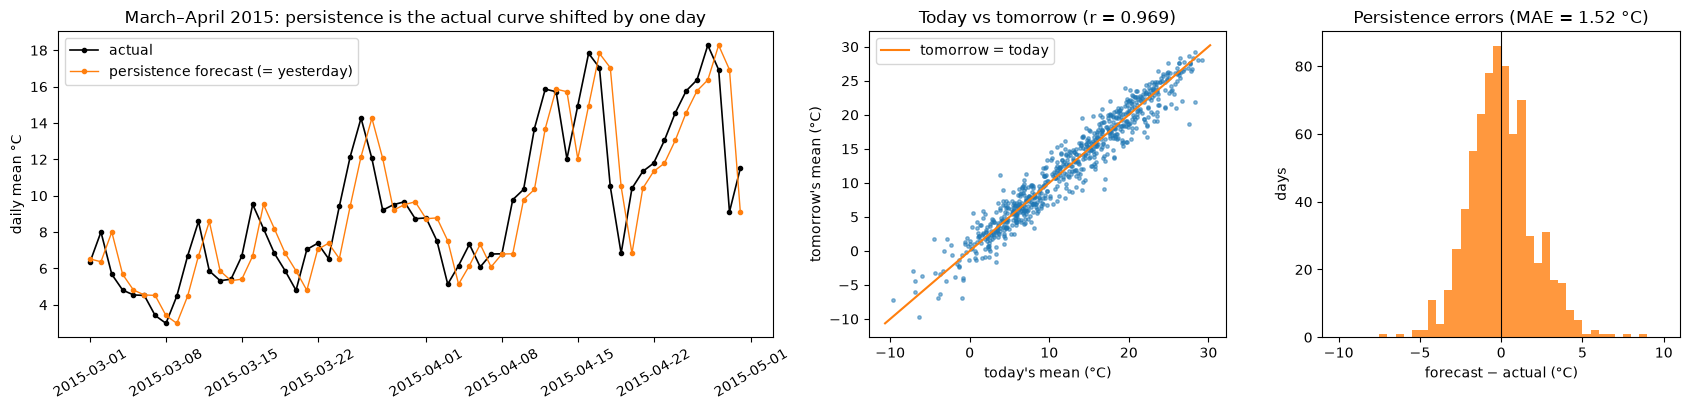

Persistence on validation: MAE 1.52 °C | within 1 °C on 42 % of days, within 2 °C on 72 % | off by more than 4 °C on 5.1 % of days
Climatology on validation: MAE 2.85 °C – knowing the season alone is much worse than knowing yesterday
Persistence for the min and max (today's min/max): min 2.02 °C, max 2.33 °C


In [25]:

d_va, y_va, p_va = ds.dates[va], ds.y[va], ds.last_mean[va]
err = p_va - y_va
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw={"width_ratios": [2, 1, 1]})

z = (d_va >= "2015-03-01") & (d_va <= "2015-04-30")
ax[0].plot(d_va[z], y_va[z], "k-o", ms=3, lw=1.2, label="actual")
ax[0].plot(d_va[z], p_va[z], "-o", color="tab:orange", ms=3, lw=1, label="persistence forecast (= yesterday)")
ax[0].set_title("March–April 2015: persistence is the actual curve shifted by one day"); ax[0].set_ylabel("daily mean °C")
ax[0].legend(); ax[0].tick_params(axis="x", rotation=30)

ax[1].scatter(p_va, y_va, s=6, alpha=0.5)
lim = [min(p_va.min(), y_va.min()) - 1, max(p_va.max(), y_va.max()) + 1]
ax[1].plot(lim, lim, color="tab:orange", lw=1.5, label="tomorrow = today")
ax[1].set_xlabel("today's mean (°C)"); ax[1].set_ylabel("tomorrow's mean (°C)")
ax[1].set_title(f"Today vs tomorrow (r = {np.corrcoef(p_va, y_va)[0, 1]:.3f})"); ax[1].legend()

ax[2].hist(err, bins=np.arange(-10, 10.5, 0.5), color="tab:orange", alpha=0.8)
ax[2].axvline(0, color="k", lw=0.8)
ax[2].set_title(f"Persistence errors (MAE = {np.abs(err).mean():.2f} °C)"); ax[2].set_xlabel("forecast − actual (°C)"); ax[2].set_ylabel("days")
plt.tight_layout(); plt.show()

a = np.abs(err)
print(f"Persistence on validation: MAE {a.mean():.2f} °C | within 1 °C on {100 * (a <= 1).mean():.0f} % of days, "
      f"within 2 °C on {100 * (a <= 2).mean():.0f} % | off by more than 4 °C on {100 * (a > 4).mean():.1f} % of days")
print(f"Climatology on validation: MAE {baselines['climatology (average for this day of year)']:.2f} °C – "
      f"knowing the season alone is much worse than knowing yesterday")
print("Persistence for the min and max (today's min/max): "
      + ", ".join(f"{t} {baselines_val.loc[t, 'persistence (tomorrow = today)']:.2f} °C" for t in ["min", "max"]))


**The goal of the project follows from this:**
- Persistence is within 1 °C on 42 % of days and within 2 °C on 72 %. It's only badly wrong (> 4 °C) on about 5 % of days, right after sudden changes.
- Knowing the season alone (climatology, 2.85 °C) is much worse than knowing yesterday (1.52 °C).
- **Goal: beat "tomorrow = today" for each target.** On validation that means below 1.52 °C (mean), 2.02 °C (min) and 2.33 °C (max). Min and max are harder: they depend on a single hour (night or afternoon), not on the whole day.
- Persistence already gets the level right, so a model can only add value by **anticipating changes**. That's why all networks predict the change from today, and why the inputs include signals of change: the pressure trend, wind direction and the evening temperature trend.

The same three views **with our model added** are shown in §10, on the test period.

## 7. Models – one comparison for all three targets

**What we compare.** Every candidate network is defined up front in `config.yaml → candidates`, with the reason for trying it. Each is combined with three **output designs**:

| Output design | What the network predicts |
|---|---|
| **single** | one network per target: separate models for the mean, the min and the max |
| **joint** | one network with 3 outputs (mean, min, max); the targets share what the network learns |
| **hourly24** | one network predicting the next day's **24 hourly temperatures**; mean, min and max are taken from that curve |

| Candidate | Why it's in the comparison |
|---|---|
| **Dense (Class 2 baseline)** | the course's starting point for tabular data, exactly as taught (absolute target, no dropout, lr 0.001) |
| **Dense (shared settings)** | the same architecture with the shared settings below; separates the effect of the settings from the architecture |
| **Daily GRU** | reads the 3 days in order (Class 2, `language.ipynb`) instead of a flat list of numbers |
| **Hourly GRU** | daily averages hide the daily cycle and the latest hours (§3), so it reads all 72 hours |
| **Two-branch GRU** | hourly detail + compact daily summaries (min/max, pressure change, trends) together |
| **Two-branch GRU + attention** | a learned weight per hour, so the model can focus on the most informative hours |

**Shared settings** (`config.yaml → common`), fixed before the comparison:
- **Predict the change** from today, not the value itself. Tomorrow is very close to today (autocorrelation 0.97, §3), so the network only has to learn the difference, and persistence is its starting point.
- **Dropout 0.4, a small `Dense(32)` head, learning rate 0.0003.** The dataset is small (~2,900 training days) and overfits easily (Class 2: "if overfitting → add Dropout"). The values come from preliminary experiments (appendix).
- MSE loss, Adam, batch 32, early stopping on validation loss (patience 15), 3 seeds.

**How we judge.** Every configuration is trained with **blocked K-fold over years**: 5 folds (2006–07, …, 2014–15), each validated once while training on the other years, 3 seeds per fold. That's 15 runs per configuration (`regression.ipynb` uses K-fold for small data; whole years avoid temporal leakage). We report MAE in °C for each target. We also report the **seed ensemble**: in each fold, the average of the 3 seeds' predictions.

**Experiment log.** Each training run is identified by its configuration, seed and fold and appended to `runs/experiments.jsonl` (predictions in `runs/preds/`). When the notebook runs again, finished runs are read from the log instead of retrained. The same configuration and seed give exactly the same result (§11), so this changes nothing in the results. **Delete `runs/experiments.jsonl` and `runs/preds/` to retrain everything.**

In [26]:
LOG = RUNS / "experiments.jsonl"


def key_of(params, seed, fold):
    s = json.dumps(params, sort_keys=True) + f"|{seed}|{fold}"
    return hashlib.sha1(s.encode()).hexdigest()[:16]


def load_cache():
    if not LOG.exists():
        return {}
    return {r["key"]: r for r in map(json.loads, LOG.read_text().splitlines())}


CACHE = load_cache()
print(len(CACHE), "finished runs found in the log")


PREDS = RUNS / "preds"


def run(ds, params, seed, fold, phase, label, train_m, val_m, save_pred=False):
    k = key_of(params, seed, fold)
    if k in CACHE and (not save_pred or (PREDS / f"{k}.npz").exists()):
        return CACHE[k]
    t0 = time.time()
    res = train_eval(ds, params, seed, train_m, val_m, keep_pred=save_pred)
    if save_pred:
        PREDS.mkdir(exist_ok=True)
        np.savez(PREDS / f"{k}.npz", **{t: v.astype("float32") for t, v in res.pop("val_pred").items()})
    if k in CACHE:      # only the predictions were missing; keep the original log entry
        return CACHE[k]
    rec = {"key": k, "phase": phase, "label": label, "seed": seed, "fold": fold,
           "params": params, **res, "seconds": round(time.time() - t0, 1)}
    with LOG.open("a") as f:
        f.write(json.dumps(rec) + "\n")
    CACHE[k] = rec
    print(f"  {phase:8s} {label:45s} seed {seed:5d} fold {fold}: val MAE {res['val_mae']:.3f}  "
          f"({res['epochs_run']} ep, {rec['seconds']}s)", flush=True)
    return rec


def score(ds, cfg, params, phase, label):
    tr, va = ds.mask("train"), ds.mask("val")
    maes = [run(ds, params, s, "val", phase, label, tr, va)["val_mae"] for s in cfg["seeds"]]
    return float(np.mean(maes)), float(np.std(maes, ddof=1))


def describe(variant):
    return ", ".join(f"{k}={v}" for k, v in variant.items())

1050 finished runs found in the log


In [27]:
DEFAULTS_NEW = {"aux": "none", "attention": False}


def norm(p):
    """Drop options that are at their default, so equivalent configurations share one log entry."""
    return {k: v for k, v in p.items() if not (k in DEFAULTS_NEW and DEFAULTS_NEW[k] == v)}


def make_params(cand, output, target=None):
    """Full parameter set for a candidate network with a given output design."""
    if cand["params"] == "baseline":
        p = dict(CONFIG["baseline"])
    else:
        p = {**CONFIG["baseline"], **CONFIG["common"], **cand["params"]}
    if output == "single":
        p["target_var"] = target
    else:
        p["aux"] = {"joint": "minmax", "hourly24": "hourly24"}[output]
    return norm(p)


def cv_folds():
    for years in CONFIG["cv"]["folds"]:
        fva = ds.mask("years", years)
        yield f"{years[0]}-{years[-1]}", ds.mask("trainval") & ~fva, fva


def cv_eval(p, phase, label):
    """Blocked K-fold (5 folds x 3 seeds) for one configuration: MAE per target for single models
    and for the seed ensemble (average of the 3 seeds' predictions in each fold)."""
    p = norm(p)
    runs, epochs, ens = {}, [], {}
    for fold, ftr, fva in cv_folds():
        fold_preds = {}
        for s in CONFIG["seeds"]:
            r = run(ds, p, s, fold, phase, label, ftr, fva, save_pred=True)
            epochs.append(r["best_epoch"])
            pred = np.load(PREDS / f"{r['key']}.npz")
            for t in pred.files:
                runs.setdefault(t, []).append(r[f"val_mae_{t}"])
                fold_preds.setdefault(t, []).append(pred[t])
        for t, ps in fold_preds.items():
            ens.setdefault(t, []).append(np.mean(np.abs(np.mean(ps, 0) - TRUTH[t][fva])))
    return {"params": p, "median_best_epoch": int(np.median(epochs)),
            "runs": {t: np.array(v) for t, v in runs.items()},
            "mae": {t: float(np.mean(v)) for t, v in runs.items()},
            "std": {t: float(np.std(v, ddof=1)) for t, v in runs.items()},
            "ens": {t: float(np.mean(v)) for t, v in ens.items()}}


def paired(a, b):
    """Paired comparison on the same 15 (fold, seed) runs: mean of b - a, its standard error and
    t = mean / SE. |t| > 2 means the difference is unlikely to be noise."""
    d = b - a
    se = d.std(ddof=1) / np.sqrt(len(d))
    return d.mean(), se, d.mean() / se

### 7.1 Every network on every target

In [28]:
results = []          # one row per (candidate, output design, target)
cv_res = {}           # configuration -> K-fold result
for cand in CONFIG["candidates"]:
    for out in cand.get("outputs", CONFIG["outputs"]):
        designs = [(make_params(cand, out, t), [t]) for t in CONFIG["targets"]] if out == "single" \
            else [(make_params(cand, out), CONFIG["targets"])]
        for p, ts in designs:
            key = json.dumps(p, sort_keys=True)
            cv_res[key] = cv_eval(p, "compare", f"{cand['name']} | {out}")
            for t in ts:
                r = cv_res[key]
                results.append({"model": cand["name"], "output": out, "target": t, "cv_mae": r["mae"][t],
                                "cv_std": r["std"][t], "ensemble_mae": r["ens"][t], "config": key})
results = pd.DataFrame(results)
print(f"{results['config'].nunique()} network configurations, "
      f"{sum(len(next(iter(r['runs'].values()))) for r in cv_res.values())} training runs")

28 network configurations, 420 training runs


### 7.2 Baselines and classic machine learning on the same folds

Persistence and climatology, plus two classic models on the same inputs and target (change from today): **Ridge regression** (linear, L2-regularised, alpha chosen by K-fold) and **gradient-boosted trees**, usually the strongest classic method on tabular data. They answer: is a neural network needed at all?

In [29]:
# Baselines and classic ML on exactly the same folds, for each target.
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_flat = np.concatenate([ds.X_daily.reshape(len(ds.y), -1), ds.X_hourly.reshape(len(ds.y), -1), ds.X_cal], 1)


def classic_cv(name, make_model, target, seeds):
    """Classic model on the K-fold folds (target = change from today, like the networks). Cached in the log."""
    maes = []
    for fold, ftr, fva in cv_folds():
        for s in seeds:
            k = key_of({"classic": name, "target": target}, s, fold)
            if k not in CACHE:
                m = make_model(s).fit(X_flat[ftr], (TRUTH[target] - TODAY[target])[ftr])
                mae = float(np.mean(np.abs(m.predict(X_flat[fva]) + TODAY[target][fva] - TRUTH[target][fva])))
                CACHE[k] = {"key": k, "phase": "classic", "label": name, "seed": s, "fold": fold,
                            "params": {"classic": name, "target": target}, "val_mae": mae}
                with LOG.open("a") as f:
                    f.write(json.dumps(CACHE[k]) + "\n")
            maes.append(CACHE[k]["val_mae"])
    return float(np.mean(maes))


ref_rows = []
for t in CONFIG["targets"]:
    pers, clim_m = [], []
    for fold, ftr, fva in cv_folds():
        pers.append(np.mean(np.abs(TODAY[t][fva] - TRUTH[t][fva])))
        c = (pd.Series(TRUTH[t][ftr], index=ds.dates[ftr].dayofyear).groupby(level=0).mean()
             .reindex(range(1, 367)).interpolate().rolling(15, center=True, min_periods=1).mean())
        clim_m.append(np.mean(np.abs(c.loc[ds.dates[fva].dayofyear].to_numpy() - TRUTH[t][fva])))
    ridge = {a: classic_cv(f"ridge_{a}", lambda s, a=a: make_pipeline(StandardScaler(), Ridge(alpha=a)), t, [0])
             for a in CONFIG["classic"]["ridge_alphas"]}
    best_a = min(ridge, key=ridge.get)
    print(f"Ridge, next-day {t}: best alpha = {best_a:g}")
    hgb = classic_cv("hgb", lambda s: HistGradientBoostingRegressor(
        **CONFIG["classic"]["hgb"], early_stopping=True, validation_fraction=0.1, n_iter_no_change=30,
        random_state=s), t, CONFIG["seeds"])
    ref_rows += [{"model": "Persistence (tomorrow = today)", "target": t, "cv_mae": np.mean(pers)},
                 {"model": "Climatology (day-of-year average)", "target": t, "cv_mae": np.mean(clim_m)},
                 {"model": "Ridge regression", "target": t, "cv_mae": ridge[best_a]},
                 {"model": "Gradient boosting", "target": t, "cv_mae": hgb}]
refs = pd.DataFrame(ref_rows)
refs.pivot(index="model", columns="target", values="cv_mae")[CONFIG["targets"]].round(3)

Ridge, next-day mean: best alpha = 1000
Ridge, next-day min: best alpha = 10
Ridge, next-day max: best alpha = 1000


target,mean,min,max
model,,,
Climatology (day-of-year average),3.114,2.950,3.984
Gradient boosting,1.221,1.371,1.946
Persistence (tomorrow = today),1.654,2.046,2.356
Ridge regression,1.288,1.354,2.033


### 7.3 Results

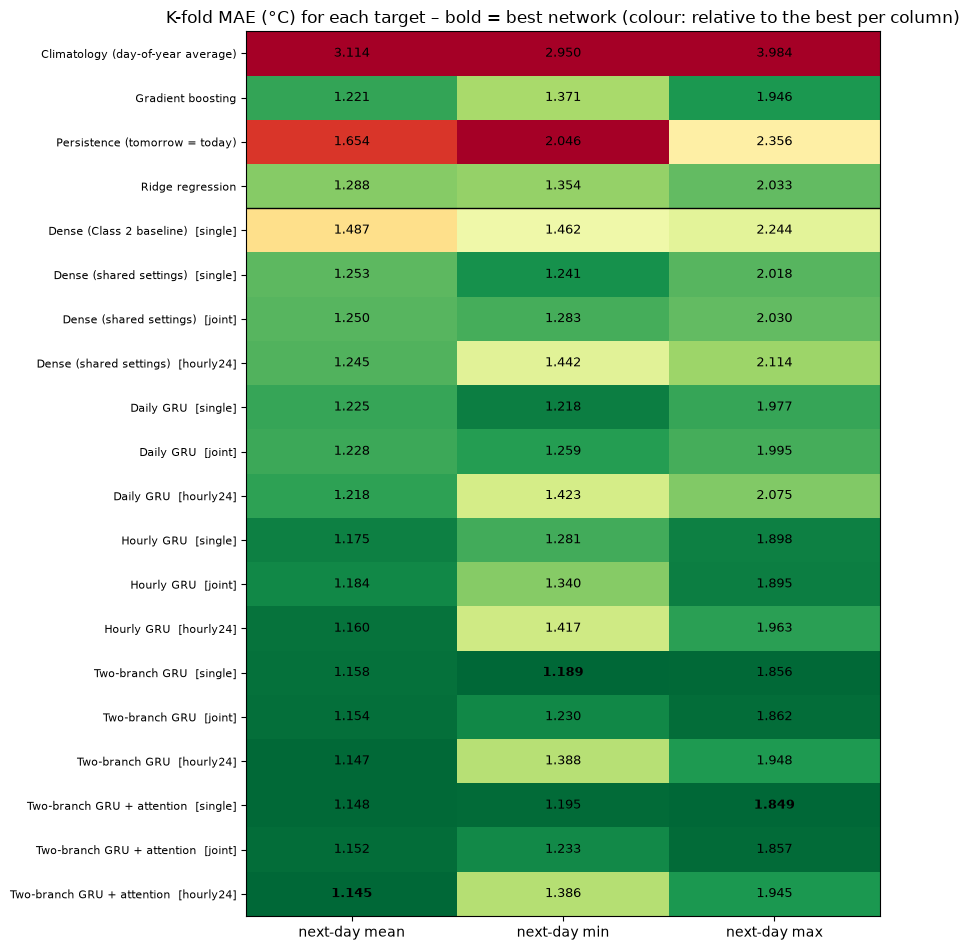

target                                       mean    min    max
Climatology (day-of-year average) –         3.114  2.950  3.984
Gradient boosting                 –         1.221  1.371  1.946
Persistence (tomorrow = today)    –         1.654  2.046  2.356
Ridge regression                  –         1.288  1.354  2.033
Dense (Class 2 baseline)          single    1.487  1.462  2.244
Dense (shared settings)           single    1.253  1.241  2.018
                                  joint     1.250  1.283  2.030
                                  hourly24  1.245  1.442  2.114
Daily GRU                         single    1.225  1.218  1.977
                                  joint     1.228  1.259  1.995
                                  hourly24  1.218  1.423  2.075
Hourly GRU                        single    1.175  1.281  1.898
                                  joint     1.184  1.340  1.895
                                  hourly24  1.160  1.417  1.963
Two-branch GRU                    single    1.158  1.189  1.856
                                  joint     1.154  1.230  1.862
                                  hourly24  1.147  1.388  1.948
Two-branch GRU + attention        single    1.148  1.195  1.849
                                  joint     1.152  1.233  1.857
                                  hourly24  1.145  1.386  1.945

In [30]:
table = results.pivot_table(index=["model", "output"], columns="target", values="cv_mae")[CONFIG["targets"]]
order = [c["name"] for c in CONFIG["candidates"]]
table = table.reindex(sorted(table.index, key=lambda i: (order.index(i[0]), CONFIG["outputs"].index(i[1]))))
ref_table = refs.pivot(index="model", columns="target", values="cv_mae")[CONFIG["targets"]]
ref_table.index = pd.MultiIndex.from_tuples([(m, "–") for m in ref_table.index])
full = pd.concat([ref_table, table])

fig, ax = plt.subplots(figsize=(9, 0.42 * len(full) + 1.2))
vals = full.to_numpy()
im = ax.imshow(vals / vals.min(axis=0), cmap="RdYlGn_r", vmin=1.0, vmax=1.5, aspect="auto")
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        best = vals[i, j] == np.nanmin(vals[len(ref_table):, j]) and i >= len(ref_table)
        ax.text(j, i, f"{vals[i, j]:.3f}", ha="center", va="center", fontsize=9, fontweight="bold" if best else None)
ax.set_xticks(range(len(CONFIG["targets"])), [f"next-day {t}" for t in CONFIG["targets"]])
ax.set_yticks(range(len(full)), [f"{m}  [{o}]" if o != "–" else m for m, o in full.index], fontsize=8)
ax.axhline(len(ref_table) - 0.5, color="k", lw=1)
ax.set_title("K-fold MAE (°C) for each target – bold = best network (colour: relative to the best per column)")
plt.tight_layout(); plt.show()
full.round(3)

**What the comparison shows** (K-fold MAE in °C, each cell = 15 runs):
- **Every network beats "tomorrow = today" on every target**, even the Class 2 baseline exactly as taught (mean 1.487 vs 1.654).
- **The shared settings matter more than any architecture.** The same Dense network goes from 1.487 to 1.253 (mean), 1.462 to 1.241 (min) and 2.244 to 2.018 (max) just by predicting the change, adding dropout and lowering the learning rate.
- **Reading the days in order helps a little.** Daily GRU vs flat Dense: 1.225 vs 1.253 (mean).
- **The hourly input is what helps the mean and the max.** Daily GRU → hourly GRU: 1.225 → 1.175 (mean), 1.977 → 1.898 (max). For the **min** it's the opposite (1.218 → 1.281): the daily rows contain yesterday's minimum and summaries directly. The **two-branch** network has both, and it's the best or nearly the best on all three targets.
- **Attention changes almost nothing** (≤ 0.01 °C either way).
- **The output design depends on the target, and here the differences are large.**
  - For the **mean**, predicting the 24-hour curve is slightly best (1.145).
  - For the **min and max**, the curve is clearly worst (min 1.386 vs 1.189; max 1.945 vs 1.849).
  - Why: trained with MSE, each predicted hour is pulled towards its average, so the curve's peaks and lows are flattened. Its average is still accurate, but its minimum and maximum are not extreme enough.
  - Separate models (*single*) are best for the min and max; the joint 3-output network is in between.
- **Is a neural network needed?**
  - Gradient-boosted trees are a strong benchmark (1.221 / 1.371 / 1.946): better than every Dense and daily-only network on the mean.
  - The best networks still beat them on every target: by 0.08 °C (mean, −6 %), 0.18 °C (min, −13 %) and 0.10 °C (max, −5 %). What makes the difference is reading the hourly and daily sequences with GRUs.
  - Ridge regression (alpha chosen per target) is clearly weaker.

### 7.4 Choice per target

For each target we choose the network with the lowest K-fold MAE. The table also shows the runner-up and whether the lead is clearly real (paired *t* over the same 15 runs; |t| > 2) or within noise. If the seed ensemble beats single models on K-fold, it's the final predictor.

In [31]:
# Final choice per target: the network configuration with the lowest K-fold MAE on that target.
# Its seed ensemble is used as the final predictor if it beats single models on K-fold.
final = {}
for t in CONFIG["targets"]:
    rt = results[results["target"] == t].sort_values("cv_mae")
    best, second = rt.iloc[0], rt[rt["config"] != rt.iloc[0]["config"]].iloc[0]
    rb, rs = cv_res[best["config"]], cv_res[second["config"]]
    diff, se, tval = paired(rb["runs"][t], rs["runs"][t])
    final[t] = {"model": best["model"], "output": best["output"], "params": rb["params"],
                "epochs": rb["median_best_epoch"], "cv_mae": rb["mae"][t], "ensemble_mae": rb["ens"][t],
                "seed_ensemble": rb["ens"][t] < rb["mae"][t],
                "runner_up": f"{second['model']} [{second['output']}]", "lead": diff, "lead_t": tval}
sel = pd.DataFrame(final).T[["model", "output", "cv_mae", "ensemble_mae", "runner_up", "lead", "lead_t", "epochs"]]
sel.columns = ["chosen network", "output design", "K-fold MAE", "seed ensemble MAE", "runner-up",
               "runner-up worse by (°C)", "t (paired)", "epochs for final training"]
(RUNS / "final_config.json").write_text(json.dumps(
    {t: {k: (bool(v) if isinstance(v, (np.bool_, bool)) else v) for k, v in f.items()
         if k in ("model", "output", "params", "epochs", "seed_ensemble")} for t, f in final.items()}, indent=2))
sel.round(3)

,chosen network,output design,K-fold MAE,seed ensemble MAE,runner-up,runner-up worse by (°C),t (paired),epochs for final training
mean,Two-branch GRU + attention,hourly24,1.144849,1.122773,Two-branch GRU [hourly24],0.002608,0.825195,91
min,Two-branch GRU,single,1.189322,1.166509,Two-branch GRU + attention [single],0.005258,1.377507,83
max,Two-branch GRU + attention,single,1.849453,1.824335,Two-branch GRU [single],0.007047,1.158514,57


**The chosen networks:**

| Next-day | Chosen network | K-fold MAE | Seed ensemble | Runner-up (worse by, *t*) |
|---|---|---|---|---|
| mean | Two-branch GRU + attention, **24-hour curve** | 1.145 | **1.123** | two-branch GRU, 24-hour curve (+0.003, t = 0.8) |
| min | Two-branch GRU, **separate model** | 1.189 | **1.167** | the same + attention (+0.005, t = 1.4) |
| max | Two-branch GRU + attention, **separate model** | 1.849 | **1.824** | the same without attention (+0.007, t = 1.2) |

- **Different targets get different models, and that's expected.** The clear difference is the **output design**: the mean is best taken from a predicted 24-hour curve, while the min and max need their own models. Both effects are far outside the noise (0.10–0.20 °C).
- **Attention or not is within noise** for every target (|t| < 2). We still apply the rule fixed in advance (lowest K-fold MAE) instead of choosing by hand. §8 shows that removing attention wouldn't change anything measurable.
- **The seed ensemble** (average of the 3 seeds) improves every target by about 0.02 °C on K-fold, so the final predictor for each target is a 3-seed average.
- **Final training length:** the median best epoch over the 15 K-fold runs, i.e. 91 (mean), 83 (min) and 57 (max) epochs.

## 8. Why each part of the chosen models is there

For each chosen network we **remove or replace one component at a time** (`config.yaml → justification`) and run the full K-fold again. We do the same for each **group of input features** (`feature_ablation`). The cost of removing something is the paired difference to the chosen model on the target(s) it was chosen for, with its standard error and *t*. A clearly positive cost (t > 2) means the part earns its place.

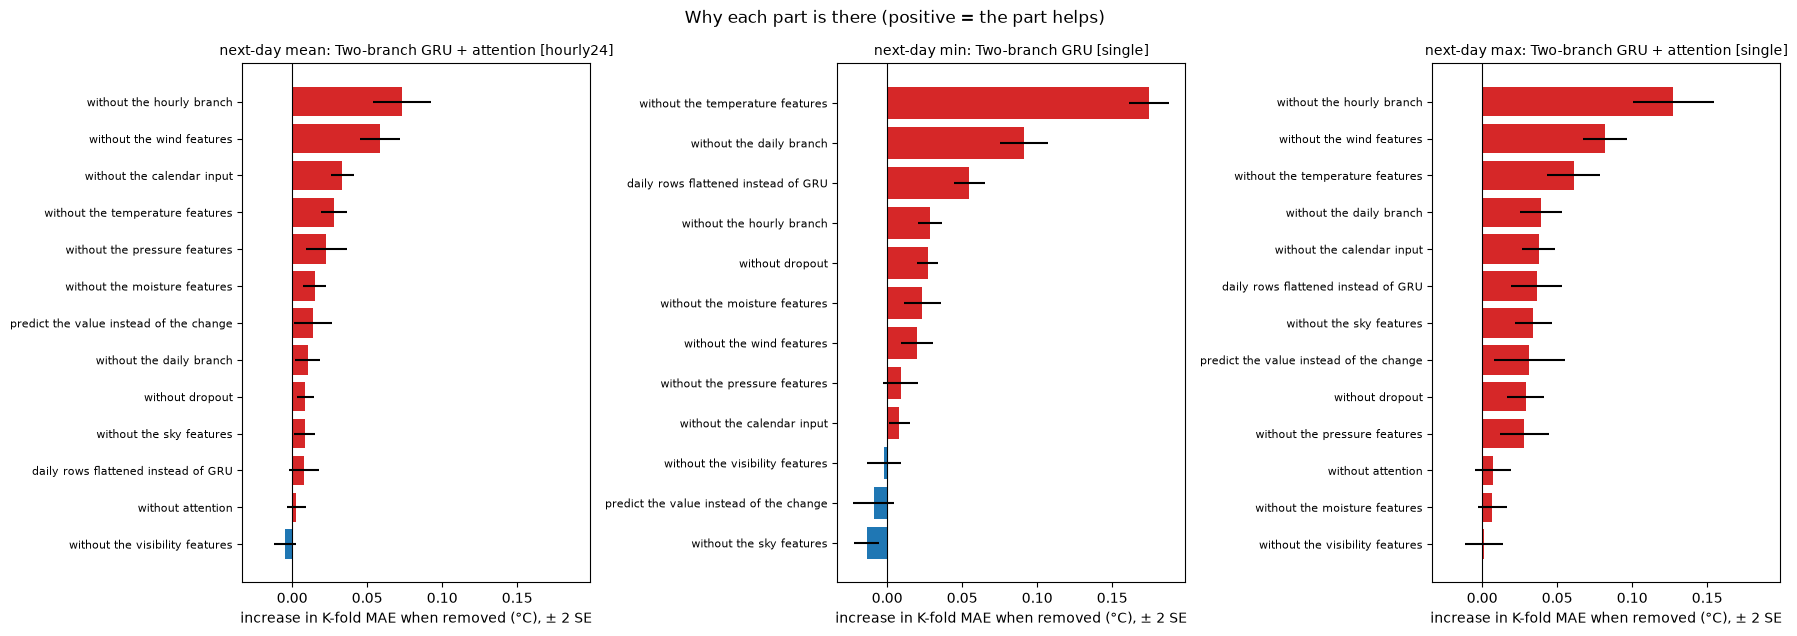

cost (°C)                    t  \
target                                       mean    min    max   mean   
removed                                                                  
daily rows flattened instead of GRU         0.008  0.055  0.036  1.598   
predict the value instead of the change     0.014 -0.009  0.031  2.206   
without attention                           0.003    NaN  0.007  0.825   
without dropout                             0.009  0.027  0.029  3.114   
without the calendar input                  0.033  0.008  0.038  8.980   
without the daily branch                    0.010  0.091  0.039  2.521   
without the hourly branch                   0.073  0.028  0.128  7.505   
without the moisture features               0.015  0.024  0.007  4.043   
without the pressure features               0.023  0.009  0.028  3.320   
without the sky features                    0.008 -0.014  0.034  2.356   
without the temperature features            0.028  0.175  0.061  6.317   
without the visibility features            -0.005 -0.002  0.001 -1.259   
without the wind features                   0.058  0.020  0.082  8.754   

                                                         
target                                      min     max  
removed                                                  
daily rows flattened instead of GRU      10.846   4.207  
predict the value instead of the change  -1.313   2.663  
without attention                           NaN   1.159  
without dropout                           7.409   4.607  
without the calendar input                2.263   6.960  
without the daily branch                 11.404   5.646  
without the hourly branch                 7.179   9.461  
without the moisture features             3.850   1.408  
without the pressure features             1.523   3.430  
without the sky features                 -3.266   5.538  
without the temperature features         26.011   6.849  
without the visibility features          -0.389   0.187  
without the wind features                 3.785  11.021

In [32]:
just_rows = []
chosen = {}                                   # configuration -> targets it was chosen for
for t, f in final.items():
    chosen.setdefault(json.dumps(f["params"], sort_keys=True), []).append(t)
for key, ts in chosen.items():
    base = cv_res[key]
    p0 = base["params"]
    variants = [(j["name"], norm({**p0, **j["change"]})) for j in CONFIG["justification"]]
    variants += [(f"without the {g} features", norm({**p0, "drop_groups": [g]})) for g in CONFIG["feature_ablation"]]
    for name, p in variants:
        if p == p0:                           # component not part of this model -> nothing to remove
            continue
        r = cv_eval(p, "justify", name)
        for t in ts:
            if t not in r["runs"]:
                continue
            diff, se, tval = paired(base["runs"][t], r["runs"][t])
            just_rows.append({"target": t, "model": final[t]["model"], "removed": name,
                              "kind": "feature group" if name.endswith("features") else "component",
                              "cost (°C)": diff, "SE": se, "t": tval})
just = pd.DataFrame(just_rows)
just.round(4).to_csv(RUNS / "justification_cv.csv", index=False)

fig, axes = plt.subplots(1, len(CONFIG["targets"]), figsize=(6 * len(CONFIG["targets"]), 0.38 * just.groupby("target").size().max() + 1.5), sharex=True)
for ax, t in zip(np.atleast_1d(axes), CONFIG["targets"]):
    j = just[just["target"] == t].sort_values("cost (°C)")
    ax.barh(j["removed"], j["cost (°C)"], xerr=2 * j["SE"],
            color=["tab:red" if v > 0 else "tab:blue" for v in j["cost (°C)"]])
    ax.axvline(0, color="k", lw=0.8); ax.tick_params(axis="y", labelsize=8)
    ax.set_title(f"next-day {t}: {final[t]['model']} [{final[t]['output']}]", fontsize=10)
    ax.set_xlabel("increase in K-fold MAE when removed (°C), ± 2 SE")
plt.suptitle("Why each part is there (positive = the part helps)"); plt.tight_layout(); plt.show()
order_t = [t for t in CONFIG["targets"] if t in set(just["target"])]
pd.concat({"cost (°C)": just.pivot_table(index="removed", columns="target", values="cost (°C)")[order_t],
           "t": just.pivot_table(index="removed", columns="target", values="t")[order_t]}, axis=1).round(3)

**What each part is worth** (increase in K-fold MAE when it's removed; t > 2 = clearly useful):

| Part | mean | min | max | Conclusion |
|---|---|---|---|---|
| hourly branch | +0.073 (t 7.5) | +0.028 (t 7.2) | +0.128 (t 9.5) | essential, most of all for the max (the afternoon peak) |
| daily branch | +0.010 (t 2.5) | +0.091 (t 11.4) | +0.040 (t 5.6) | essential for the min |
| GRU over the 3 daily rows (vs flattened) | +0.008 (t 1.6) | +0.055 (t 10.8) | +0.036 (t 4.2) | useful for min and max |
| dropout 0.4 | +0.009 (t 3.1) | +0.027 (t 7.4) | +0.029 (t 4.6) | useful everywhere: the data is small |
| calendar (day of year) | +0.033 (t 9.0) | +0.008 (t 2.3) | +0.038 (t 7.0) | useful everywhere |
| predicting the change | +0.014 (t 2.2) | −0.009 (t −1.3) | +0.032 (t 2.7) | useful for mean and max; neutral for the min |
| attention | +0.003 (t 0.8) | – | +0.007 (t 1.2) | **not measurably useful** |

| Feature group | mean | min | max |
|---|---|---|---|
| temperature | +0.028 (t 6.3) | **+0.175 (t 26.0)** | +0.061 (t 6.8) |
| wind | **+0.058 (t 8.8)** | +0.020 (t 3.8) | **+0.082 (t 11.0)** |
| pressure | +0.023 (t 3.3) | +0.009 (t 1.5) | +0.028 (t 3.4) |
| moisture (humidity, dew point) | +0.015 (t 4.0) | +0.024 (t 3.9) | +0.007 (t 1.4) |
| sky (cloudiness, fog, windy) | +0.008 (t 2.4) | **−0.014 (t −3.3)** | +0.034 (t 5.5) |
| visibility | −0.005 (t −1.3) | −0.002 (t −0.4) | +0.001 (t 0.2) |

**Conclusions**
- **Almost every part earns its place.** Both branches, the GRU over the daily rows, dropout and the calendar are clearly useful for at least two targets.
- **Wind and pressure**, the weather-front signals found in §3, are among the most useful inputs for the mean and the max. Recent temperature is what the min depends on most.
- **Three parts are not justified:**
  - Attention is neutral.
  - Visibility is neutral for every target, as §3 predicted.
  - For the min, the sky features even make the model slightly worse.
- **We report these instead of acting on them.** The selection rule was fixed in advance. Removing parts after looking at their ablation, and in our case after the test evaluation, would make the K-fold estimate too optimistic. The expected gain is small anyway (≈ 0.01 °C). A next iteration would start with a simpler model: no attention, no visibility, and no sky features for the min.

## 9. The final models

Live demonstration (seed 123, trained here): learning curves of the Class 2 baseline and of the network chosen for the **mean**, and the architecture of the chosen network(s).

Class 2 baseline (mean)                                : validation MAE (mean) 1.476 °C (best epoch 17)


chosen for the mean: Two-branch GRU + attention        : validation MAE (mean) 1.093 °C (best epoch 82)


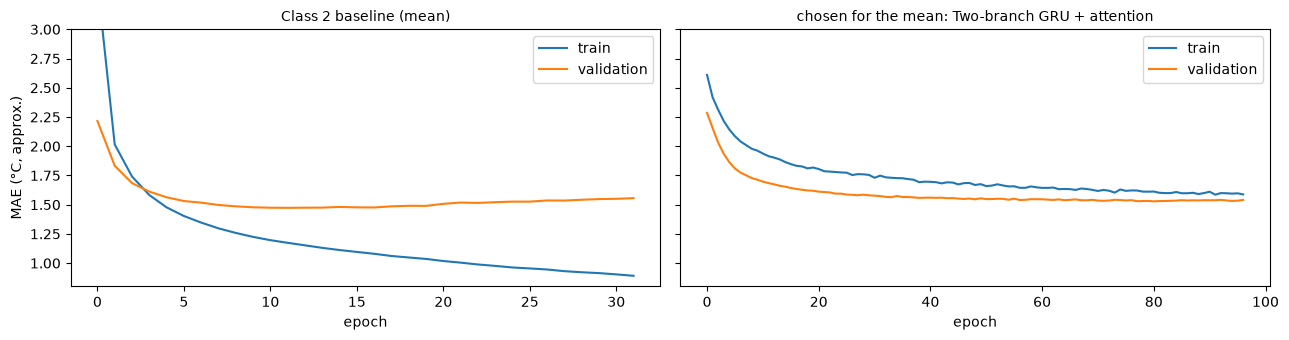

In [33]:
demo = {}
for name, p in [("Class 2 baseline (mean)", CONFIG["baseline"]), (f"chosen for the mean: {final['mean']['model']}", final["mean"]["params"])]:
    res, model, prep, hist = train_eval(ds, p, 123, tr, va, return_model=True)
    demo[name] = (model, prep, hist)
    print(f"{name:55s}: validation MAE (mean) {res['val_mae_mean']:.3f} °C (best epoch {res['best_epoch']})")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5), sharey=True)
for a, (name, (_, prep, hist)) in zip(ax, demo.items()):
    a.plot(np.array(hist.history["mae"]) * np.mean(prep.sd_y), label="train")
    a.plot(np.array(hist.history["val_mae"]) * np.mean(prep.sd_y), label="validation")
    a.set_title(name, fontsize=10); a.set_xlabel("epoch"); a.legend()
ax[0].set_ylabel("MAE (°C, approx.)"); ax[0].set_ylim(0.8, 3)
plt.tight_layout(); plt.show()

In [34]:
for key, ts in chosen.items():
    p = cv_res[key]["params"]
    prep = Prepared(ds, tr, p)
    shapes = {k: v.shape[1:] for k, v in prep.inputs(tr).items()}
    m = build_model(p, shapes, 0)
    print(f"Chosen for: {', '.join(ts)}  –  {final[ts[0]]['model']} [{final[ts[0]]['output']}], "
          f"{m.count_params():,} parameters, trained {final[ts[0]]['epochs']} epochs")
    print("  differences from the Class 2 baseline:", {k: v for k, v in p.items() if CONFIG['baseline'].get(k) != v})

Chosen for: mean  –  Two-branch GRU + attention [hourly24], 13,305 parameters, trained 91 epochs
  differences from the Class 2 baseline: {'input': 'both', 'daily_arch': 'gru', 'dense': [32], 'dropout': 0.4, 'target': 'delta', 'lr': 0.0003, 'attention': True, 'aux': 'hourly24'}
Chosen for: min  –  Two-branch GRU [single], 11,489 parameters, trained 83 epochs
  differences from the Class 2 baseline: {'input': 'both', 'daily_arch': 'gru', 'dense': [32], 'dropout': 0.4, 'target': 'delta', 'lr': 0.0003, 'target_var': 'min'}
Chosen for: max  –  Two-branch GRU + attention [single], 12,546 parameters, trained 57 epochs
  differences from the Class 2 baseline: {'input': 'both', 'daily_arch': 'gru', 'dense': [32], 'dropout': 0.4, 'target': 'delta', 'lr': 0.0003, 'attention': True, 'target_var': 'max'}


**The final networks**

All three share the same structure; they differ only in the output and in whether attention is used:

```
72 hourly rows × 13 features ─► GRU(32) ─► [attention: score per hour → softmax → weighted sum] ⊕ last state ─┐
3 daily rows × 16 features ──► GRU(32) ─────────────────────────────────────────────────────────────────────┼─► Dense(32, relu) ─► Dropout(0.4) ─► output
day of year of tomorrow (sin, cos) ─────────────────────────────────────────────────────────────────────────┘
```

| Next-day | Output | Parameters |
|---|---|---|
| mean | `Dense(24)`: tomorrow's 24 hourly temperatures as changes from today's mean; the prediction is their average | 13,305 |
| min | `Dense(1)`: change from today's min | 11,489 (no attention) |
| max | `Dense(1)`: change from today's max | 12,546 |

- **Why it looks like this:**
  - Hourly GRU: the daily cycle and the latest hours (§3, §7).
  - Daily GRU: compact summaries and trends, essential for the min (§8).
  - Calendar: the season.
  - Small head with dropout: ~2,900 training days, so the model must stay small (≈ 12k parameters) and regularised.
- **Learning curves.**
  - **Class 2 baseline:** overfits after about 15 epochs. Training error keeps falling while validation error rises (best epoch 17, validation 1.476 °C).
  - **Chosen network:** learns slowly and steadily (learning rate 0.0003), with no sign of overfitting by epoch 82 (validation 1.093 °C on 2014–2015).
  - Its training error lies *above* the validation error because dropout is only active during training.

## 10. Final result on the test period

Each chosen network is retrained from scratch on **2006–2015** (train + validation, as in the "training the final model" step of `regression.ipynb`) with 3 seeds, for the number of epochs chosen by K-fold. The final prediction is the average of the 3 seeds. It is evaluated on **1 January – 3 November 2016** (308 days; the rest of 2016 is artificial, Issue 9), which was never used for any modelling decision. Earlier evaluations of the test year are listed in the appendix.

In [35]:
# Retrain each chosen network on 2006-2015 (3 seeds) and predict the test period once.
if CONFIG["run_test"]:
    tv, te = ds.mask("trainval"), ds.mask("test")
    out = RUNS / "final"; out.mkdir(exist_ok=True)
    test_preds = {}                                   # configuration -> {target: [pred per seed]}
    hourly_curves = {}
    for key, ts in chosen.items():
        f = final[ts[0]]
        for s in CONFIG["seeds"]:
            _, model, prep, _ = train_eval(ds, f["params"], s, tv, epochs=f["epochs"],
                                           log_csv=out / f"history_{'_'.join(ts)}_seed_{s}.csv", return_model=True)
            model.save(out / f"model_{'_'.join(ts)}_seed_{s}.keras")
            raw_pred = model.predict(prep.inputs(te), verbose=0, batch_size=1024)
            for t, pr in prep.targets_celsius(raw_pred, te).items():
                test_preds.setdefault(key, {}).setdefault(t, []).append(pr)
            if f["params"].get("aux") == "hourly24":
                hourly_curves.setdefault(key, []).append(
                    raw_pred * prep.sd_y + prep.mu_y + (ds.last_mean[te][:, None] if f["params"]["target"] == "delta" else 0))
    tp = pd.DataFrame({"date": ds.dates[te]})
    summary = {"test_days": int(te.sum()), "period": f"{ds.dates[te].min().date()} – {ds.dates[te].max().date()}"}
    for t in CONFIG["targets"]:
        key = json.dumps(final[t]["params"], sort_keys=True)
        seeds_pred = test_preds[key][t]
        ens_t = np.mean(seeds_pred, axis=0)
        tp[f"actual_{t}"], tp[f"pred_{t}"], tp[f"persistence_{t}"] = TRUTH[t][te], ens_t, TODAY[t][te]
        single = [float(np.mean(np.abs(sp - TRUTH[t][te]))) for sp in seeds_pred]
        clim_t = (pd.Series(TRUTH[t][tv], index=ds.dates[tv].dayofyear).groupby(level=0).mean()
                  .reindex(range(1, 367)).interpolate().rolling(15, center=True, min_periods=1).mean())
        summary[t] = {"model": f"{final[t]['model']} [{final[t]['output']}]",
                      "seed_ensemble_mae": float(np.mean(np.abs(ens_t - TRUTH[t][te]))),
                      "single_mae_mean": float(np.mean(single)), "single_mae_std": float(np.std(single, ddof=1)),
                      "persistence_mae": float(np.mean(np.abs(TODAY[t][te] - TRUTH[t][te]))),
                      "climatology_mae": float(np.mean(np.abs(clim_t.loc[ds.dates[te].dayofyear].to_numpy() - TRUTH[t][te])))}
    for key, curves in hourly_curves.items():
        np.save(out / "test_hourly_predictions.npy", np.mean(curves, axis=0).astype("float32"))
    (out / "test_summary.json").write_text(json.dumps(summary, indent=2))
    tp.to_csv(out / "test_predictions.csv", index=False)
else:
    print("run_test is false in config.yaml – the test set is not used.")

In [36]:
test = json.loads((RUNS / "final" / "test_summary.json").read_text())
tp = pd.read_csv(RUNS / "final" / "test_predictions.csv", parse_dates=["date"])
print(f"Test period: {test['period']} ({test['test_days']} days)\n")
rows = []
for t in CONFIG["targets"]:
    s = test[t]
    rows.append({"next-day": t, "chosen network": s["model"], "final model (3-seed average)": s["seed_ensemble_mae"],
                 "single models (mean ± std)": f"{s['single_mae_mean']:.3f} ± {s['single_mae_std']:.3f}",
                 "tomorrow = today": s["persistence_mae"], "climatology": s["climatology_mae"],
                 "better than persistence": f"{100 * (1 - s['seed_ensemble_mae'] / s['persistence_mae']):.0f} %"})
pd.DataFrame(rows).set_index("next-day").round(3)

Test period: 2016-01-01 – 2016-11-03 (308 days)



,chosen network,final model (3-seed average),single models (mean ± std),tomorrow = today,climatology,better than persistence
next-day,,,,,,
mean,Two-branch GRU + attention [hourly24],1.152,1.173 ± 0.019,1.673,2.842,31 %
min,Two-branch GRU [single],1.126,1.153 ± 0.009,2.185,2.769,48 %
max,Two-branch GRU + attention [single],1.988,2.008 ± 0.012,2.553,3.679,22 %


### The persistence picture from §6 – now with our model

The same three views as in §6, on unseen test days (March–April 2016, the same weeks one year later). "Tomorrow = today" is just the actual curve shifted by one day; the model has to **anticipate** the change.

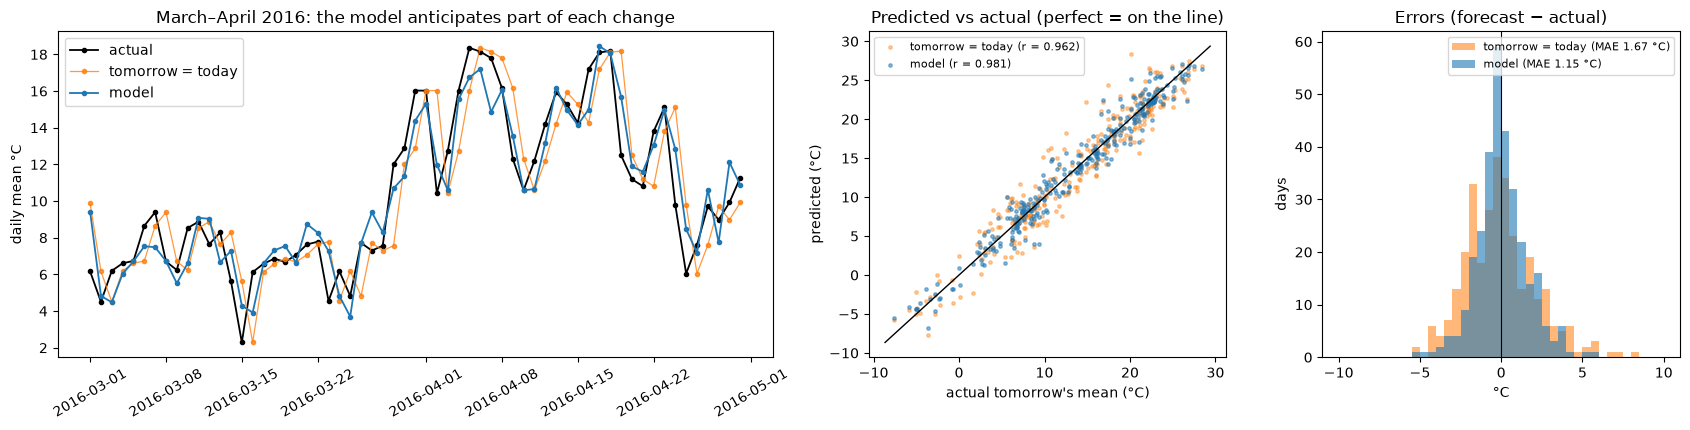

tomorrow = today : within 1 °C on 40 % of days, within 2 °C on 67 % | off by more than 4 °C on 7.5 % of days
model            : within 1 °C on 56 % of days, within 2 °C on 82 % | off by more than 4 °C on 1.9 % of days


In [37]:
err_model_d = tp["pred_mean"] - tp["actual_mean"]
err_pers_d = tp["persistence_mean"] - tp["actual_mean"]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4), gridspec_kw={"width_ratios": [2, 1, 1]})
z = (tp["date"] >= "2016-03-01") & (tp["date"] <= "2016-04-30")
ax[0].plot(tp["date"][z], tp["actual_mean"][z], "k-o", ms=3, lw=1.3, label="actual")
ax[0].plot(tp["date"][z], tp["persistence_mean"][z], "-o", color="tab:orange", ms=3, lw=0.9, alpha=0.8, label="tomorrow = today")
ax[0].plot(tp["date"][z], tp["pred_mean"][z], "-o", color="tab:blue", ms=3, lw=1.3, label="model")
ax[0].set_title("March–April 2016: the model anticipates part of each change"); ax[0].set_ylabel("daily mean °C")
ax[0].legend(); ax[0].tick_params(axis="x", rotation=30)
cols = ["actual_mean", "pred_mean", "persistence_mean"]
lim = [tp[cols].min().min() - 1, tp[cols].max().max() + 1]
ax[1].scatter(tp["actual_mean"], tp["persistence_mean"], s=6, alpha=0.4, color="tab:orange",
              label=f"tomorrow = today (r = {tp['actual_mean'].corr(tp['persistence_mean']):.3f})")
ax[1].scatter(tp["actual_mean"], tp["pred_mean"], s=6, alpha=0.5, color="tab:blue",
              label=f"model (r = {tp['actual_mean'].corr(tp['pred_mean']):.3f})")
ax[1].plot(lim, lim, color="k", lw=1)
ax[1].set_xlabel("actual tomorrow's mean (°C)"); ax[1].set_ylabel("predicted (°C)")
ax[1].set_title("Predicted vs actual (perfect = on the line)"); ax[1].legend(fontsize=8)
bins = np.arange(-10, 10.5, 0.5)
ax[2].hist(err_pers_d, bins=bins, color="tab:orange", alpha=0.55, label=f"tomorrow = today (MAE {err_pers_d.abs().mean():.2f} °C)")
ax[2].hist(err_model_d, bins=bins, color="tab:blue", alpha=0.6, label=f"model (MAE {err_model_d.abs().mean():.2f} °C)")
ax[2].axvline(0, color="k", lw=0.8)
ax[2].set_title("Errors (forecast − actual)"); ax[2].set_xlabel("°C"); ax[2].set_ylabel("days"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
for name, e in [("tomorrow = today", err_pers_d), ("model", err_model_d)]:
    a = e.abs()
    print(f"{name:17s}: within 1 °C on {100 * (a <= 1).mean():.0f} % of days, within 2 °C on {100 * (a <= 2).mean():.0f} % | "
          f"off by more than 4 °C on {100 * (a > 4).mean():.1f} % of days")

- **The model is not a shifted copy of the actual curve.** Before a change it already moves part of the way, e.g. the drop around 15 March or the warm-up at the end of March. It rarely gets the full size of a big change.
- **Over the 308 test days, the model is far more often close to the truth:**

  | | within 1 °C | within 2 °C | off by more than 4 °C |
  |---|---|---|---|
  | model | 56 % of days | 82 % | 1.9 % |
  | tomorrow = today | 40 % | 67 % | 7.5 % |

- Correlation with the actual mean: 0.981 vs 0.962. The error histogram is narrower and has fewer large errors.

### Mean, min and max over the whole test period

Each panel shows the actual value (black), the chosen model (blue) and **"tomorrow = today"** (orange): today's mean, min and max respectively.

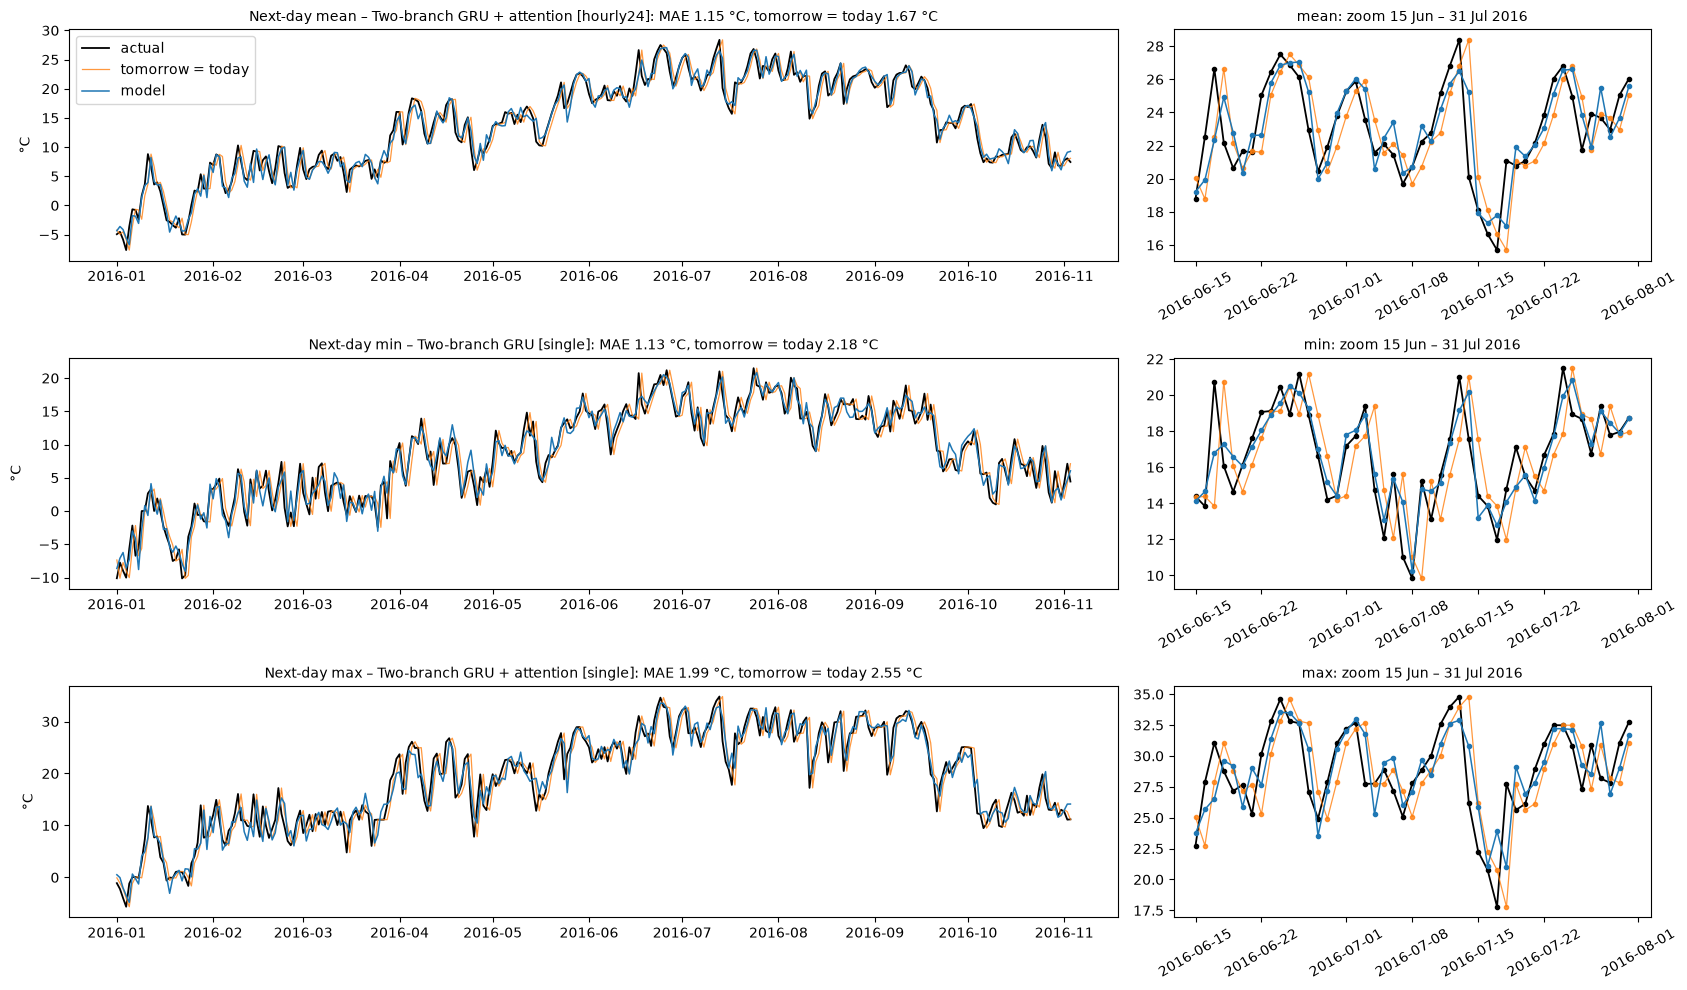

In [38]:
zoom = (tp["date"] >= "2016-06-15") & (tp["date"] <= "2016-07-31")
fig, axes = plt.subplots(3, 2, figsize=(17, 10), gridspec_kw={"width_ratios": [2.2, 1]})
for t, (ax_full, ax_zoom) in zip(CONFIG["targets"], axes):
    a, p, b = f"actual_{t}", f"pred_{t}", f"persistence_{t}"
    for ax, m, kw in [(ax_full, slice(None), {}), (ax_zoom, zoom, {"marker": "o", "ms": 3})]:
        ax.plot(tp["date"][m], tp[a][m], color="k", lw=1.3, label="actual", **kw)
        ax.plot(tp["date"][m], tp[b][m], color="tab:orange", lw=0.9, alpha=0.8, label="tomorrow = today", **kw)
        ax.plot(tp["date"][m], tp[p][m], color="tab:blue", lw=1.1, label="model", **kw)
    ax_full.set_title(f"Next-day {t} – {test[t]['model']}: MAE {test[t]['seed_ensemble_mae']:.2f} °C, "
                      f"tomorrow = today {test[t]['persistence_mae']:.2f} °C", fontsize=10)
    ax_zoom.set_title(f"{t}: zoom 15 Jun – 31 Jul 2016", fontsize=10); ax_zoom.tick_params(axis="x", rotation=30)
    ax_full.set_ylabel("°C")
axes[0, 0].legend(loc="upper left")
plt.tight_layout(); plt.show()

**The 24-hour curve** behind the predictions, for three test days: a typical day (median error), the day with the largest error, and the cold front of 14 July. The orange line repeats today's 24 hours.

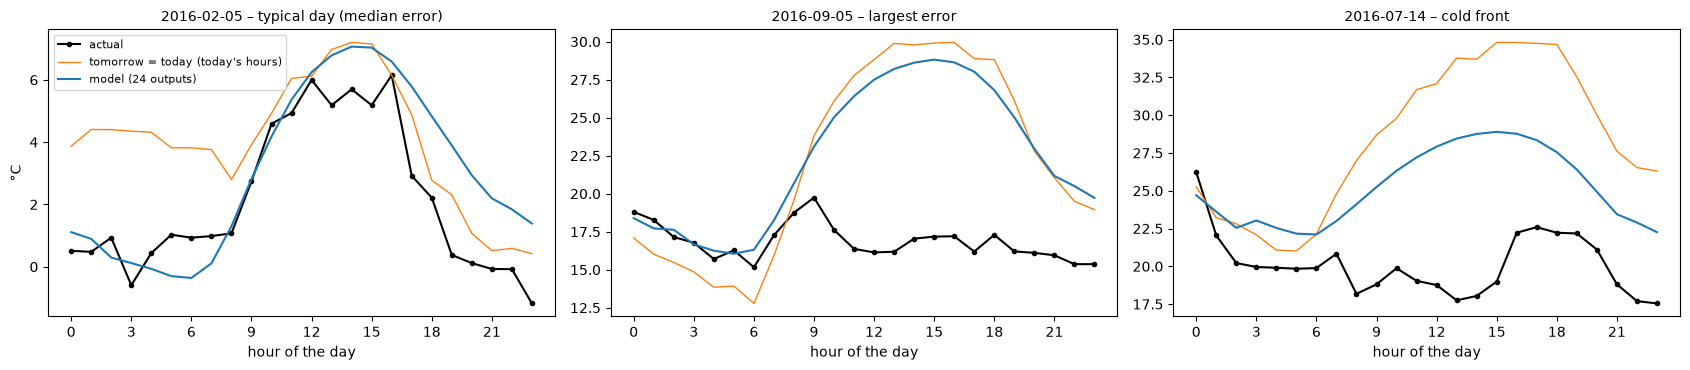

In [39]:
hp_path = RUNS / "final" / "test_hourly_predictions.npy"
if hp_path.exists():
    te = ds.mask("test")
    pred_h, actual_h = np.load(hp_path), ds.y_hourly[te]
    today_h = ds.X_hourly[te][:, -24:, ds.hourly_cols.index("temp")]
    err = (tp["pred_mean"] - tp["actual_mean"]).abs()
    picks = {"typical day (median error)": int((err - err.median()).abs().idxmin()),
             "largest error": int(err.idxmax()), "cold front": int(tp.index[tp["date"] == "2016-07-14"][0])}
    fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
    for ax, (title, k) in zip(axes, picks.items()):
        ax.plot(range(24), actual_h[k], "k-o", ms=3, label="actual")
        ax.plot(range(24), today_h[k], color="tab:orange", lw=1, label="tomorrow = today (today's hours)")
        ax.plot(range(24), pred_h[k], color="tab:blue", lw=1.5, label="model (24 outputs)")
        ax.set_title(f"{tp['date'][k].date()} – {title}", fontsize=10)
        ax.set_xlabel("hour of the day"); ax.set_xticks(range(0, 24, 3))
    axes[0].set_ylabel("°C"); axes[0].legend(fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print("No network with the 24-hour output was chosen, so there is no hourly curve to show.")

**What the three targets show**
- **Min: the largest gain, −48 %** (1.13 vs 2.18 °C).
  - Today's minimum is a poor guess, because the night minimum depends on the coming night.
  - The model sees the last evening hours, which are only a few hours before tomorrow's early-morning minimum, and their trend.
- **Mean: −31 %** (1.15 vs 1.67 °C).
- **Max: the smallest gain, −22 %** (1.99 vs 2.55 °C).
  - The afternoon peak is 15+ hours away and depends on tomorrow's sunshine.
  - None of our inputs describes tomorrow's sky, so the model only gets the part that follows from wind, pressure and the season.
- **The 24-hour curves** explain why separate models were better for the min and the max:
  - The predicted curve has the right shape and level on a typical day, but it's smooth.
  - On the day with the largest error (5 September), the model predicted a normal warm day. The day turned out cool and flat after 9:00 (probably a front or rain), with little warning in the previous 3 days.
  - For the cold front of 14 July, the model lowered the afternoon peak by about 6 °C compared with today. That's the right direction, but still 6–7 °C too warm.

### Goal check: did we beat "tomorrow = today"?

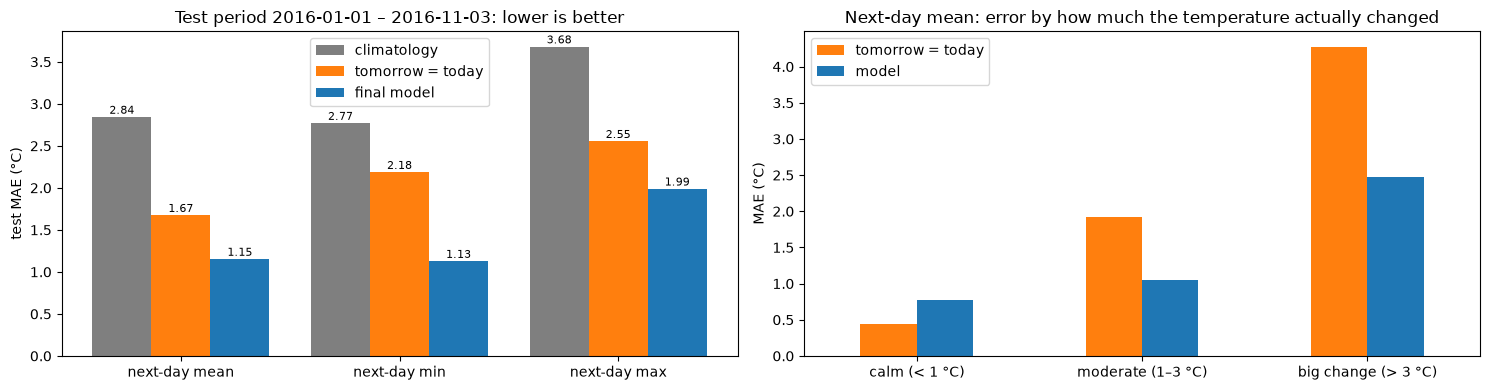

Model closer to the truth than persistence (mean) on 66 % of the 308 test days


,days,tomorrow = today,model
calm (< 1 °C),123,0.45,0.78
moderate (1–3 °C),140,1.91,1.06
big change (> 3 °C),45,4.27,2.47


In [40]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
labels = [f"next-day {t}" for t in CONFIG["targets"]]
x = np.arange(len(labels)); w = 0.27
for k, (name, key, color) in enumerate([("climatology", "climatology_mae", "tab:gray"),
                                        ("tomorrow = today", "persistence_mae", "tab:orange"),
                                        ("final model", "seed_ensemble_mae", "tab:blue")]):
    v = [test[t][key] for t in CONFIG["targets"]]
    bars = axes[0].bar(x + (k - 1) * w, v, w, label=name, color=color)
    for b_, val in zip(bars, v):
        axes[0].text(b_.get_x() + b_.get_width() / 2, val + 0.04, f"{val:.2f}", ha="center", fontsize=8)
axes[0].set_xticks(x, labels); axes[0].set_ylabel("test MAE (°C)"); axes[0].legend()
axes[0].set_title(f"Test period {test['period']}: lower is better")

chg = (tp["actual_mean"] - tp["persistence_mean"]).abs()
err_model = (tp["pred_mean"] - tp["actual_mean"]).abs()
err_pers = (tp["persistence_mean"] - tp["actual_mean"]).abs()
bins_c = pd.cut(chg, [0, 1, 3, 20], labels=["calm (< 1 °C)", "moderate (1–3 °C)", "big change (> 3 °C)"], include_lowest=True)
by = pd.DataFrame({"days": bins_c.value_counts().sort_index(),
                   "tomorrow = today": err_pers.groupby(bins_c, observed=False).mean(),
                   "model": err_model.groupby(bins_c, observed=False).mean()})
by[["tomorrow = today", "model"]].plot.bar(ax=axes[1], color=["tab:orange", "tab:blue"], rot=0)
axes[1].set_title("Next-day mean: error by how much the temperature actually changed"); axes[1].set_ylabel("MAE (°C)")
plt.tight_layout(); plt.show()
print(f"Model closer to the truth than persistence (mean) on {100 * (err_model < err_pers).mean():.0f} % of the {len(tp)} test days")
by.round(2)

In [41]:
big = tp.assign(error=tp["pred_mean"] - tp["actual_mean"], change=tp["actual_mean"] - tp["persistence_mean"])
worst = big.reindex(big["error"].abs().sort_values(ascending=False).index).head(5)
print("Five largest errors for the next-day mean (note the size of the day-to-day change):")
worst.assign(date=worst["date"].dt.date)[["date", "actual_mean", "pred_mean", "persistence_mean", "error", "change"]].round(1)

Five largest errors for the next-day mean (note the size of the day-to-day change):


,date,actual_mean,pred_mean,persistence_mean,error,change
248,2016-09-05,16.8,22.4,22.2,5.6,-5.3
44,2016-02-14,9.4,3.9,6.5,-5.4,2.9
195,2016-07-14,20.1,25.2,28.4,5.1,-8.3
10,2016-01-11,8.8,3.9,3.6,-4.9,5.2
54,2016-02-24,5.6,10.0,10.0,4.4,-4.4


**Test result (1 Jan – 3 Nov 2016, 308 days never used for a decision about these models)**

| Next-day | Chosen network | Model MAE | Tomorrow = today | Improvement | K-fold estimate |
|---|---|---|---|---|---|
| mean | two-branch GRU + attention, 24-hour curve | **1.152** | 1.673 | −31 % | 1.123 (−32 % vs persistence) |
| min | two-branch GRU | **1.126** | 2.185 | −48 % | 1.167 (−43 %) |
| max | two-branch GRU + attention | **1.988** | 2.553 | −22 % | 1.824 (−23 %) |

- **The goal is reached for all three targets.** The relative improvement on the test period matches the K-fold estimates.
- The max is higher in absolute terms (1.99 vs 1.82) because 2016 was harder for the max in general: persistence also gets worse, 2.55 vs 2.36.
- Averaging the 3 seeds beats the average single model by 0.02–0.03 °C on every target. The single models agree closely (std 0.01–0.02 °C).
- **Where the gain comes from.** The model is closer than persistence on 66 % of days:

  | Days by size of change | Days | Tomorrow = today | Model |
  |---|---|---|---|
  | calm, < 1 °C | 123 | **0.45** | 0.78 |
  | moderate, 1–3 °C | 140 | 1.91 | **1.06** |
  | big change, > 3 °C | 45 | 4.27 | **2.47** |

  On calm days persistence is better, because when nothing changes, "today" is almost exact and every adjustment adds error. Persistence can't know in advance which days will be calm, though.
- **The largest errors** are sudden changes with little warning in the previous 3 days. Example: 14 July (−8.3 °C). The model predicted 3.2 °C of the drop, while persistence predicted none of it.
- **Test-set disclosure:**
  - The model for the **mean** is the same configuration (and the same 91 epochs) as the final model of our previous version. That's why its test MAE is identical (1.152) to the earlier evaluation listed in the appendix.
  - The **min and max** models are new and were evaluated on the test period for the first time here.

## 11. Reproducibility check (Class 1, step 7)

Training the same configuration twice with the same seed must give exactly the same result.

In [42]:
p_fast = CONFIG["baseline"]
a = train_eval(ds, p_fast, 1, tr, va)["val_mae"]
b = train_eval(ds, p_fast, 1, tr, va)["val_mae"]
print("Reproducible:", a == b, a, b)

Reproducible: True 1.3554575443267822 1.3554575443267822


## 12. Summary, problems and lessons

**Task:** predict the next day's mean, minimum and maximum temperature from the last 3 days of weather, without `Apparent Temperature`.

**Result on the unseen test period** (MAE, °C): mean **1.15**, min **1.13**, max **1.99**. "Tomorrow = today" gets 1.67, 2.18 and 2.55, so the improvement is −31 %, −48 % and −22 %.

**How we got there**
1. **EDA and cleaning** (§2): 9 data issues found and handled. The most important were mixed time zones, duplicate rows, impossible zeros in pressure and humidity, rain labels that exist in only two years, and the artificial last 57 days of 2016.
2. **Baselines** (§6): persistence (1.52 °C on validation) is the bar to beat; climatology (2.85 °C) is much worse.
3. **One comparison** (§7):
   - 6 networks, from the Class 2 Dense baseline to a two-branch GRU with attention, with up to 3 output designs each: 28 configurations covering all 3 targets.
   - Classic ML on the same folds.
   - All evaluated with blocked K-fold over years (15 runs per configuration).
4. **Choice per target:** the two-branch GRU wins every target. The best output design differs: a 24-hour curve for the mean, separate models for the min and max.
5. **Justification** (§8): each component and feature group removed in turn. Both branches, dropout, the calendar and most feature groups are clearly useful. Attention and visibility are not.

**Problems we met**
- Data issues 1–9 (§2).
- A training fold with a constant feature (the rain flag), which made one K-fold fold explode. Fixed with `safe_std` and by removing the feature.
- The artificial days at the end of 2016, found only in the test plots.
- An order-dependent greedy search in the first version (appendix).

**Lessons**
- A strong naive baseline is essential. Here it is "tomorrow = today", and the honest question is how much a model adds to it.
- Predicting the change instead of the value, and regularising a small model, mattered more than the choice of architecture.
- The data's structure should drive the architecture: the daily cycle → hourly sequence; trends → daily sequence; the targets' nature → output design.
- With small data, differences of 0.01 °C are noise. Paired comparisons over many runs, and an ablation, keep you from over-interpreting them.

### How to reproduce
```bash
python3.12 -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt      # exact versions
jupyter lab weather_forecast.ipynb    # run all cells top to bottom
# finished runs are reused from runs/experiments.jsonl + runs/preds/; delete them to retrain everything
```

## Use of AI tools

Required by `Grading.md`. *To be reviewed and completed by the team:* the code (data pipeline, experiment search, model code) and the first draft of the explanations were produced with **Claude Code (Anthropic)**. The team reviewed every part. We must be able to explain every architectural choice, loss function and line of code; anything we can't explain gets removed.

## Appendix – how the project developed, and every use of the test period

The structure above (one comparison, chosen per target) is the final version. It was preceded by a longer exploration, which is where the **shared settings** of §7 come from.

1. **Course-style search.**
   - Starting from the Class 2 Dense baseline, we changed one setting at a time: input (daily / hourly / both), architecture, target (value / change), dropout, learning rate, and so on. Each change was kept if it helped on validation.
   - Then K-fold over years for the best configurations.
   - This greedy order missed the hourly input at first: whether a change helps depends on what was chosen before it. A second pass over all stages fixed that.
2. **Ideas beyond the course templates**, each tested with K-fold and paired *t*:
   - Promising, and therefore candidates in §7: the two-branch network, attention, the 24-hour output, the joint mean/min/max output.
   - Rejected, because they didn't help: Conv1D before the GRU, a wider network, and the `Daily Summary` text as a bag of words.
3. **The rain-feature bug.**
   - One K-fold fold produced absurd errors (MAE > 200 °C). Rain labels exist only in 2012 and 2016 (Issue 8), so in one fold the rain flag was constant in training, and scaling divided by zero.
   - We removed the feature, added `safe_std`, and reran everything.
4. **The artificial days** (Issue 9) were found in the test plots. Since then the test period ends on 3 November 2016.
5. **The restructuring** into the single comparison of §7, with all three targets from the start, replaced the earlier sequence. The earlier sequence was a single target (the mean) with the min and max as by-products.

**Every evaluation on the test period.** All scores are on the 308 real days, MAE of the next-day mean:

| # | Model | Mean | Min / max | Where |
|---|---|---|---|---|
| 1 | first search, with the rain feature | 1.337 | – | `runs/history_with_rain_feature/test_eval_1_first_pass` |
| 2 | after the second pass, with the rain feature | 1.267 | – | `runs/history_with_rain_feature/test_eval_2_second_pass` |
| 3 | single target (mean) version: two-branch GRU + attention, 24-hour curve | 1.152 | 1.320 / 2.044 (from the curve) | `runs/history_v1_single_target/final` |
| 4 | **this notebook**: one model per target | **1.152** | **1.126 / 1.988** | `runs/final` |

- No model choice was made by comparing test scores.
- But the test period was seen several times during development, and the shared settings come from the development phase in which evaluations 1–3 took place. So the test result is not entirely free of the developers' knowledge of it.
- The K-fold estimates (§7) are the cleaner measure. They agree with the test results.

**Archives:** every training run of the earlier versions is kept in `runs/history_with_rain_feature/` and `runs/history_v1_single_target/` (logs, predictions, tables).